In [1]:
!pip install earthengine-api geemap geopandas pandas matplotlib rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 30.9 MB/s  0:00:00


In [2]:
import ee

ee.Authenticate()

In [3]:
import ee

PROJECT_ID = "microclimas-cochabamba"

ee.Initialize(project=PROJECT_ID)

print("Conexión exitosa con Google Earth Engine")

Conexión exitosa con Google Earth Engine


In [4]:
collection = ee.ImageCollection(
    "COPERNICUS/S2_SR_HARMONIZED"
)

print(
    "Imágenes consultadas:",
    collection.filterDate(
        "2024-06-01",
        "2024-09-01"
    ).size().getInfo()
)

Imágenes consultadas: 1150507


In [5]:
import ee

# Área aproximada de Cochabamba para una primera consulta.
cochabamba = ee.Geometry.Point(
    [-66.1568, -17.3895]
).buffer(15000)

# Consultar Sentinel-2
sentinel = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(cochabamba)
    .filterDate("2024-06-01", "2024-09-01")
    .filter(
        ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40)
    )
)

print("Escenas Sentinel-2:", sentinel.size().getInfo())

Escenas Sentinel-2: 40


In [6]:
landsat8 = (
    ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .filterBounds(cochabamba)
    .filterDate("2024-06-01", "2024-09-01")
)

landsat9 = (
    ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    .filterBounds(cochabamba)
    .filterDate("2024-06-01", "2024-09-01")
)

print("Landsat 8:", landsat8.size().getInfo())
print("Landsat 9:", landsat9.size().getInfo())

Landsat 8: 11
Landsat 9: 11


In [7]:

import ee
import geemap

# Conectar con Earth Engine
ee.Initialize(project="microclimas-cochabamba")

# Recuperar el área de estudio aproximada
cochabamba = ee.Geometry.Point(
    [-66.1568, -17.3895]
).buffer(15000)

# Máscara de nubes Sentinel-2
def mask_sentinel(image):
    scl = image.select("SCL")

    mask = (
        scl.neq(3)
        .And(scl.neq(7))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    return image.updateMask(mask)

# Consultar imágenes
sentinel = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(cochabamba)
    .filterDate("2024-06-01", "2024-09-01")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
    .map(mask_sentinel)
)

# Calcular NDVI
def calculate_ndvi(image):
    return (
        image.normalizedDifference(["B8", "B4"])
        .rename("NDVI")
    )

ndvi_collection = sentinel.map(calculate_ndvi)

# Crear composición mediana
ndvi_median = (
    ndvi_collection
    .median()
    .clip(cochabamba)
)

print("NDVI calculado correctamente.")
print("Escenas:", sentinel.size().getInfo())
print("Bandas:", ndvi_median.bandNames().getInfo())


NDVI calculado correctamente.
Escenas: 40
Bandas: ['NDVI']


In [8]:

Map = geemap.Map(
    center=[-17.3895, -66.1568],
    zoom=10,
    basemap="Esri.WorldImagery"
)

ndvi_visualization = {
    "min": 0,
    "max": 0.8,
    "palette": [
        "#F5E6C8",
        "#D9F0DC",
        "#8BCB9A",
        "#43A875",
        "#237B5B"
    ],
    "opacity": 0.75
}

Map.addLayer(
    ndvi_median,
    ndvi_visualization,
    "NDVI - Cochabamba 2024"
)

Map.addLayer(
    cochabamba,
    {"color": "FFFFFF"},
    "Área aproximada de estudio"
)

Map.addLayerControl()
Map


Map(center=[-17.3895, -66.1568], controls=(WidgetControl(options=['position', 'transparent_bg'], position='top…

In [9]:
import requests
import geopandas as gpd
from IPython.display import display

url = "https://hogaria.com/geo/datos/distritos.geojson"

headers = {
    "User-Agent": "Mozilla/5.0"
}

respuesta = requests.get(url, headers=headers)

print("Código de respuesta:", respuesta.status_code)

if respuesta.status_code == 200:
    with open("/content/distritos.geojson", "wb") as archivo:
        archivo.write(respuesta.content)

    distritos_publicos = gpd.read_file("/content/distritos.geojson")

    print("Cantidad de elementos:", len(distritos_publicos))
    print("Sistema de coordenadas:", distritos_publicos.crs)
    print("Columnas:", distritos_publicos.columns.tolist())

    display(distritos_publicos.head())

else:
    print("No se pudo acceder al archivo.")

Código de respuesta: 200
Cantidad de elementos: 103
Sistema de coordenadas: EPSG:4326
Columnas: ['codigo', 'municipio_ine', 'codigo_distrito', 'nombre', 'fuente', 'latitud', 'longitud', 'geometry']


,codigo,municipio_ine,codigo_distrito,nombre,fuente,latitud,longitud,geometry
0,010101-distrito-1,010101,1,Distrito 1,gadch,-19.047317,-65.259489,"MULTIPOLYGON (((-65.26998 -19.05314, -65.26943..."
1,010101-distrito-2,010101,2,Distrito 2,gadch,-19.029860,-65.251657,GEOMETRYCOLLECTION (MULTIPOLYGON (((-65.23382 ...
2,010101-distrito-3,010101,3,Distrito 3,gadch,-19.026459,-65.276243,GEOMETRYCOLLECTION (MULTIPOLYGON (((-65.29025 ...
3,010101-distrito-4,010101,4,Distrito 4,gadch,-19.061520,-65.268374,GEOMETRYCOLLECTION (MULTIPOLYGON (((-65.25868 ...
4,010101-distrito-5,010101,5,Distrito 5,gadch,-19.086177,-65.286680,GEOMETRYCOLLECTION (MULTIPOLYGON (((-65.28538 ...


In [10]:
# Revisar los municipios incluidos en la capa
municipios = (
    distritos_publicos[["municipio_ine"]]
    .drop_duplicates()
    .sort_values("municipio_ine")
)

print("Códigos de municipios encontrados:")
display(municipios)

# Buscar Cochabamba: código INE 030101
cochabamba_distritos = distritos_publicos[
    distritos_publicos["municipio_ine"].astype(str).str.strip() == "030101"
].copy()

print("\nElementos encontrados para Cochabamba:",
      len(cochabamba_distritos))

print("\nDistritos encontrados:")
display(
    cochabamba_distritos[
        ["codigo", "codigo_distrito", "nombre", "fuente"]
    ].sort_values("codigo_distrito")
)

Códigos de municipios encontrados:


,municipio_ine
0,010101
5,020101
13,020105
27,030101
42,030901
52,030902
55,030903
61,030904
65,030905
70,031001



Elementos encontrados para Cochabamba: 15

Distritos encontrados:


,codigo,codigo_distrito,nombre,fuente
27,030101-distrito-1,1,Distrito 1,ciudatoslab
28,030101-distrito-10,10,Distrito 10,ciudatoslab
29,030101-distrito-11,11,Distrito 11,ciudatoslab
30,030101-distrito-12,12,Distrito 12,ciudatoslab
31,030101-distrito-13,13,Distrito 13,ciudatoslab
32,030101-distrito-14,14,Distrito 14,ciudatoslab
33,030101-distrito-15,15,Distrito 15,ciudatoslab
34,030101-distrito-2,2,Distrito 2,ciudatoslab
35,030101-distrito-3,3,Distrito 3,ciudatoslab
36,030101-distrito-4,4,Distrito 4,ciudatoslab


Total de distritos: 15
Geometrías vacías: 0
Geometrías inválidas: 0

Tipos de geometría:
MultiPolygon    15
Name: count, dtype: int64

Límites geográficos:
[-66.280266 -17.534057 -66.067174 -17.278124]


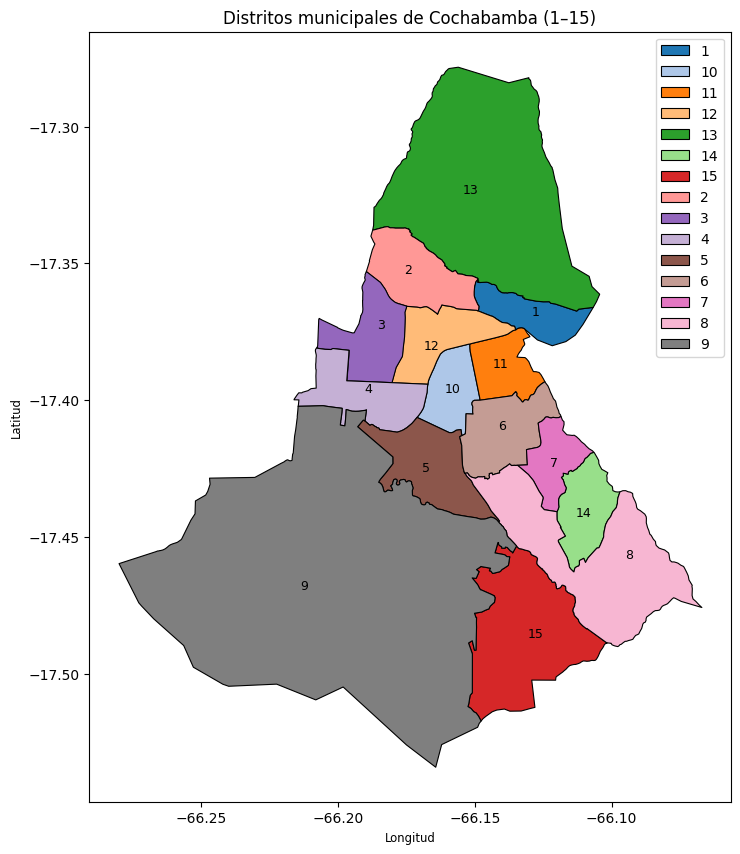

In [11]:
# 1. Ordenar los distritos numéricamente
cochabamba_distritos = cochabamba_distritos.sort_values(
    "codigo_distrito"
).copy()

# 2. Revisar la calidad de las geometrías
print("Total de distritos:", len(cochabamba_distritos))
print("Geometrías vacías:", cochabamba_distritos.geometry.is_empty.sum())
print("Geometrías inválidas:", (~cochabamba_distritos.geometry.is_valid).sum())

print("\nTipos de geometría:")
print(cochabamba_distritos.geom_type.value_counts())

# 3. Revisar extensión geográfica
print("\nLímites geográficos:")
print(cochabamba_distritos.total_bounds)

# 4. Visualizar los 15 distritos
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

cochabamba_distritos.plot(
    ax=ax,
    column="codigo_distrito",
    cmap="tab20",
    edgecolor="black",
    linewidth=0.8,
    legend=True
)

for _, distrito in cochabamba_distritos.iterrows():
    punto = distrito.geometry.representative_point()
    ax.annotate(
        str(distrito["codigo_distrito"]),
        (punto.x, punto.y),
        ha="center",
        va="center",
        fontsize=9,
        color="black"
    )

ax.set_title("Distritos municipales de Cochabamba (1–15)")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_aspect("equal")
plt.show()

In [12]:
# Exportar los 15 distritos de Cochabamba
ruta_geojson = "/content/distritos_cochabamba.geojson"

cochabamba_distritos.to_file(
    ruta_geojson,
    driver="GeoJSON"
)

print("Archivo generado correctamente:")
print(ruta_geojson)

Archivo generado correctamente:
/content/distritos_cochabamba.geojson


In [13]:
import os

print("¿Existe el archivo?", os.path.exists(ruta_geojson))
print("Tamaño en KB:", round(os.path.getsize(ruta_geojson) / 1024, 2))

¿Existe el archivo? True
Tamaño en KB: 62.99


In [14]:
import json
import ee
import geemap

ee.Initialize(project="microclimas-cochabamba")

# Leer el GeoJSON
with open("/content/distritos_cochabamba.geojson", "r") as archivo:
    geojson_data = json.load(archivo)

# Convertir a FeatureCollection de Earth Engine
distritos_ee = ee.FeatureCollection(geojson_data["features"])

print("Distritos cargados:", distritos_ee.size().getInfo())

# Crear mapa satelital
Map = geemap.Map(
    center=[-17.3895, -66.1568],
    zoom=11,
    basemap="Esri.WorldImagery"
)

# Agregar límites
Map.addLayer(
    distritos_ee.style(
        color="00FFFF",
        fillColor="00000000",
        width=2
    ),
    {},
    "Distritos de Cochabamba"
)

Map.centerObject(distritos_ee, 11)
Map

Distritos cargados: 15


Map(center=[-17.424215501513547, -66.16721085220207], controls=(WidgetControl(options=['position', 'transparen…

In [15]:
print("Total de distritos:", distritos_ee.size().getInfo())

print("\nNombres de los distritos:")
print(
    distritos_ee.aggregate_array("nombre").getInfo()
)

print("\nÁrea total aproximada (km²):")
area = distritos_ee.geometry().area(maxError=10).divide(1e6)
print(round(area.getInfo(), 2))

Total de distritos: 15

Nombres de los distritos:
['Distrito 1', 'Distrito 10', 'Distrito 11', 'Distrito 12', 'Distrito 13', 'Distrito 14', 'Distrito 15', 'Distrito 2', 'Distrito 3', 'Distrito 4', 'Distrito 5', 'Distrito 6', 'Distrito 7', 'Distrito 8', 'Distrito 9']

Área total aproximada (km²):
295.65


In [16]:
import ee

ee.Initialize(project="microclimas-cochabamba")

# Periodo de análisis
fecha_inicio = "2024-06-01"
fecha_fin = "2024-09-01"

# Máscara de nubes, sombras y píxeles defectuosos
def mask_sentinel(image):
    scl = image.select("SCL")

    mask = (
        scl.neq(3)
        .And(scl.neq(7))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    return image.updateMask(mask)

# Colección Sentinel-2
sentinel = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(distritos_ee.geometry())
    .filterDate(fecha_inicio, fecha_fin)
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
    .map(mask_sentinel)
)

print("Escenas encontradas:", sentinel.size().getInfo())

# Calcular NDVI
def calcular_ndvi(image):
    return image.normalizedDifference(
        ["B8", "B4"]
    ).rename("NDVI")

ndvi_coleccion = sentinel.map(calcular_ndvi)

# Compuesto de mediana
ndvi_municipal = (
    ndvi_coleccion
    .median()
    .clip(distritos_ee.geometry())
)

print("Compuesto NDVI generado correctamente.")

Escenas encontradas: 38
Compuesto NDVI generado correctamente.


In [17]:
# Calcular estadísticas de NDVI para cada distrito

estadisticas_ndvi = ndvi_municipal.reduceRegions(
    collection=distritos_ee,
    reducer=(
        ee.Reducer.mean()
        .combine(
            reducer2=ee.Reducer.median(),
            sharedInputs=True
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
    ),
    scale=10,
    tileScale=4
)

# Obtener resultados
resultados = estadisticas_ndvi.getInfo()

# Convertir a tabla de Pandas
import pandas as pd

datos_ndvi = pd.DataFrame([
    feature["properties"]
    for feature in resultados["features"]
])

# Ordenar numéricamente
datos_ndvi = datos_ndvi.sort_values("codigo_distrito")

display(datos_ndvi)

,codigo,codigo_distrito,fuente,latitud,longitud,max,mean,median,min,municipio_ine,nombre
0,030101-distrito-1,1,ciudatoslab,-17.367893,-66.127688,0.861083,0.191557,0.154275,-0.072499,030101,Distrito 1
1,030101-distrito-10,10,ciudatoslab,-17.395909,-66.158294,0.781663,0.132512,0.081948,-0.247781,030101,Distrito 10
2,030101-distrito-11,11,ciudatoslab,-17.386697,-66.140482,0.809309,0.232911,0.236288,-0.071197,030101,Distrito 11
3,030101-distrito-12,12,ciudatoslab,-17.380088,-66.165810,0.833563,0.182092,0.138693,-0.083663,030101,Distrito 12
4,030101-distrito-13,13,ciudatoslab,-17.323254,-66.151448,0.958040,0.314208,0.253839,-0.284921,030101,Distrito 13
5,030101-distrito-14,14,ciudatoslab,-17.441372,-66.110115,0.599498,0.139558,0.134746,-0.085446,030101,Distrito 14
6,030101-distrito-15,15,ciudatoslab,-17.485629,-66.127827,0.842938,0.167085,0.162113,-0.077793,030101,Distrito 15
7,030101-distrito-2,2,ciudatoslab,-17.352565,-66.174354,0.801524,0.180826,0.154310,-0.183183,030101,Distrito 2
8,030101-distrito-3,3,ciudatoslab,-17.372595,-66.184315,0.816844,0.171625,0.142572,-0.086727,030101,Distrito 3
9,030101-distrito-4,4,ciudatoslab,-17.396013,-66.189098,0.860113,0.145585,0.113236,-0.422266,030101,Distrito 4


In [18]:
# Máscara de píxeles con NDVI >= 0.3
vegetacion = ndvi_municipal.gte(0.3).rename("vegetacion")

# Calcular superficie en hectáreas
area_vegetacion = (
    ee.Image.pixelArea()
    .divide(10000)
    .updateMask(vegetacion)
    .rename("hectareas_vegetacion")
)

# Superficie con datos válidos de NDVI
area_valida = (
    ee.Image.pixelArea()
    .divide(10000)
    .updateMask(ndvi_municipal.mask())
    .rename("hectareas_validas")
)

# Combinar las dos bandas
imagen_areas = area_vegetacion.addBands(area_valida)

# Calcular por distrito
estadisticas_vegetacion = imagen_areas.reduceRegions(
    collection=distritos_ee,
    reducer=ee.Reducer.sum(),
    scale=10,
    tileScale=4
)

# Convertir a tabla
resultados_vegetacion = estadisticas_vegetacion.getInfo()

datos_vegetacion = pd.DataFrame([
    f["properties"]
    for f in resultados_vegetacion["features"]
])

# Calcular porcentaje
datos_vegetacion["porcentaje_vegetacion"] = (
    datos_vegetacion["hectareas_vegetacion"] /
    datos_vegetacion["hectareas_validas"]
) * 100

datos_vegetacion = datos_vegetacion.sort_values(
    "codigo_distrito"
)

display(
    datos_vegetacion[
        [
            "nombre",
            "hectareas_vegetacion",
            "hectareas_validas",
            "porcentaje_vegetacion"
        ]
    ].round(2)
)

,nombre,hectareas_vegetacion,hectareas_validas,porcentaje_vegetacion
0,Distrito 1,100.84,569.49,17.71
1,Distrito 10,72.38,560.06,12.92
2,Distrito 11,177.39,555.84,31.91
3,Distrito 12,135.38,765.38,17.69
4,Distrito 13,1780.31,4878.43,36.49
5,Distrito 14,19.02,693.88,2.74
6,Distrito 15,87.89,2122.43,4.14
7,Distrito 2,137.25,907.34,15.13
8,Distrito 3,112.24,815.73,13.76
9,Distrito 4,83.22,834.18,9.98


In [19]:
# Revisar si los distritos se superponen entre sí

distritos_metricos = cochabamba_distritos.to_crs(
    "EPSG:32719"
)

solapamientos = []

for i in range(len(distritos_metricos)):
    for j in range(i + 1, len(distritos_metricos)):

        interseccion = (
            distritos_metricos.iloc[i].geometry
            .intersection(
                distritos_metricos.iloc[j].geometry
            )
        )

        area_m2 = interseccion.area

        if area_m2 > 100:
            solapamientos.append({
                "Distrito A": distritos_metricos.iloc[i]["nombre"],
                "Distrito B": distritos_metricos.iloc[j]["nombre"],
                "Área solapada (ha)": area_m2 / 10000
            })

print("Cantidad de solapamientos:", len(solapamientos))

if solapamientos:
    display(pd.DataFrame(solapamientos))
else:
    print("No se encontraron solapamientos mayores a 100 m².")

Cantidad de solapamientos: 9


,Distrito A,Distrito B,Área solapada (ha)
0,Distrito 1,Distrito 12,0.012821
1,Distrito 1,Distrito 13,0.019490
2,Distrito 10,Distrito 6,0.047228
3,Distrito 11,Distrito 6,0.159598
4,Distrito 12,Distrito 3,2.455109
5,Distrito 2,Distrito 3,1.096459
6,Distrito 3,Distrito 4,0.030182
7,Distrito 6,Distrito 7,0.128543
8,Distrito 6,Distrito 8,0.021682


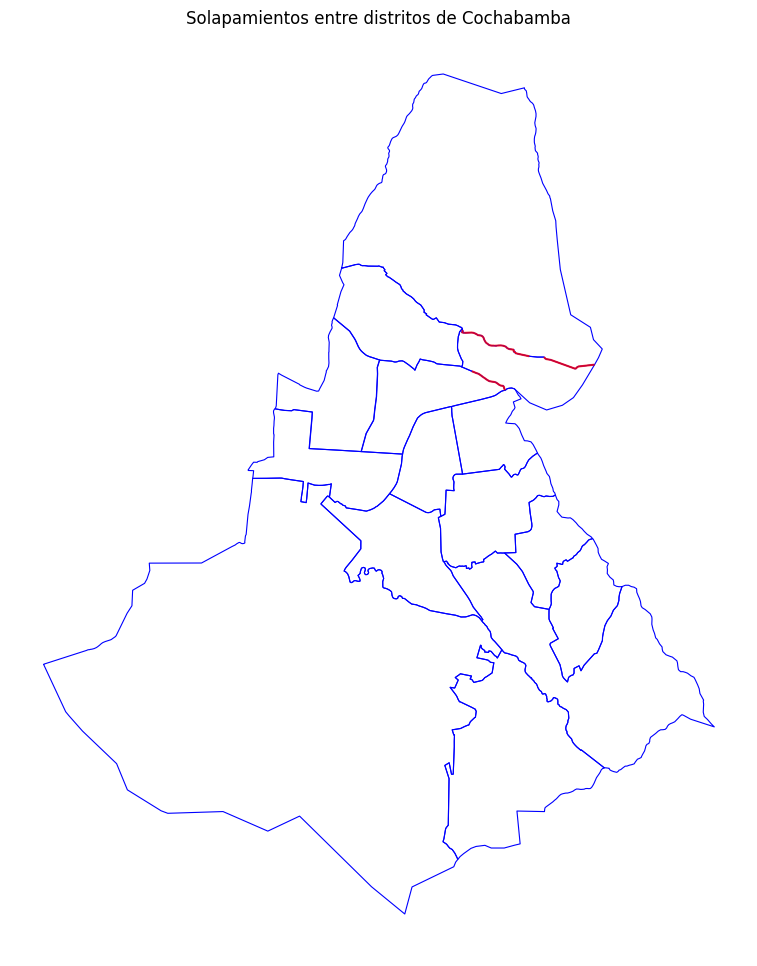

In [20]:
import matplotlib.pyplot as plt
from shapely.ops import unary_union

# Trabajar en coordenadas métricas
gdf = distritos_metricos.copy()

# Calcular las intersecciones
fig, ax = plt.subplots(figsize=(12, 12))

# Dibujar distritos
gdf.boundary.plot(
    ax=ax,
    color="blue",
    linewidth=0.8
)

# Dibujar zonas de solapamiento
for i in range(len(gdf)):
    for j in range(i + 1, len(gdf)):

        interseccion = (
            gdf.iloc[i].geometry
            .intersection(gdf.iloc[j].geometry)
        )

        if interseccion.area > 100:
            gpd.GeoSeries(
                [interseccion],
                crs=gdf.crs
            ).plot(
                ax=ax,
                color="red",
                alpha=0.8
            )

ax.set_title("Solapamientos entre distritos de Cochabamba")
ax.set_axis_off()
plt.show()

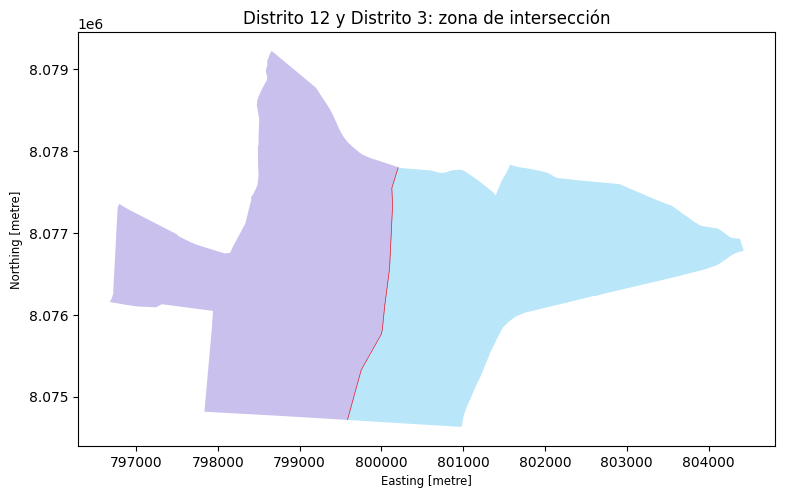

Distrito 12 vs. Distrito 3 | Área compartida: 2.4551 ha


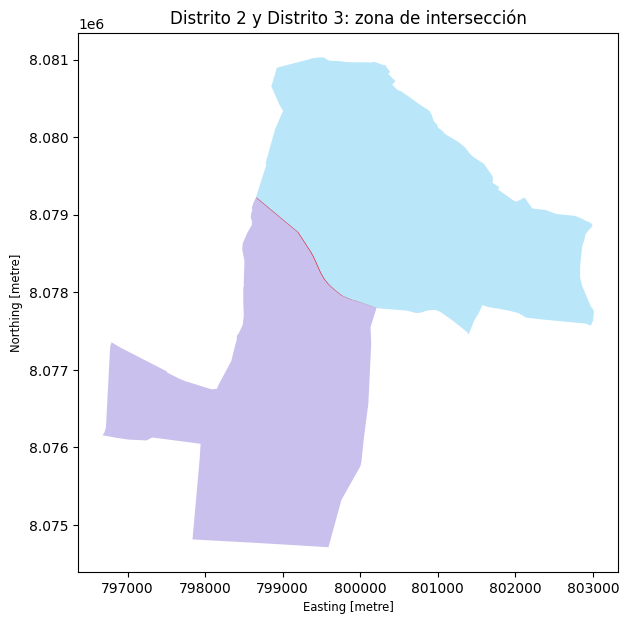

Distrito 2 vs. Distrito 3 | Área compartida: 1.0965 ha


In [21]:
import matplotlib.pyplot as plt
import geopandas as gpd

pares = [
    ("Distrito 12", "Distrito 3"),
    ("Distrito 2", "Distrito 3")
]

for nombre_a, nombre_b in pares:

    a = gdf[gdf["nombre"] == nombre_a].geometry.iloc[0]
    b = gdf[gdf["nombre"] == nombre_b].geometry.iloc[0]

    interseccion = a.intersection(b)

    fig, ax = plt.subplots(figsize=(9, 7))

    gpd.GeoSeries([a], crs=gdf.crs).plot(
        ax=ax, color="#65C8F2", alpha=0.45
    )

    gpd.GeoSeries([b], crs=gdf.crs).plot(
        ax=ax, color="#8875D8", alpha=0.45
    )

    gpd.GeoSeries([interseccion], crs=gdf.crs).plot(
        ax=ax, color="red", alpha=0.9
    )

    ax.set_title(f"{nombre_a} y {nombre_b}: zona de intersección")
    ax.set_aspect("equal")
    plt.show()

    print(
        nombre_a, "vs.", nombre_b,
        "| Área compartida:",
        round(interseccion.area / 10000, 4), "ha"
    )

Área de huecos dentro del contorno (ha): 7615.9669


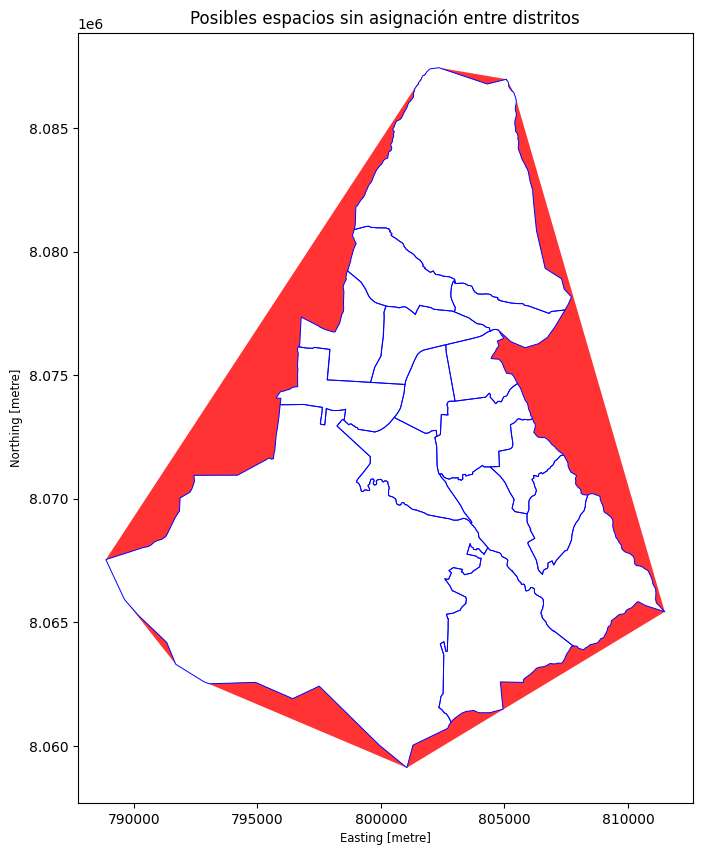

In [22]:
from shapely.ops import unary_union
import geopandas as gpd
import matplotlib.pyplot as plt

# Unir los 15 distritos
union_distritos = unary_union(gdf.geometry)

# Crear el contorno general de los distritos
contorno = union_distritos.convex_hull

# Detectar espacios que quedan dentro del contorno,
# pero fuera de los polígonos de los distritos
huecos = contorno.difference(union_distritos)

print("Área de huecos dentro del contorno (ha):",
      round(huecos.area / 10000, 4))

# Visualizar
fig, ax = plt.subplots(figsize=(10, 10))

gdf.boundary.plot(ax=ax, color="blue", linewidth=0.7)

gpd.GeoSeries([huecos], crs=gdf.crs).plot(
    ax=ax,
    color="red",
    alpha=0.8
)

ax.set_title("Posibles espacios sin asignación entre distritos")
ax.set_aspect("equal")
plt.show()

In [23]:
from shapely.ops import unary_union
import geopandas as gpd
import matplotlib.pyplot as plt

# Unir todos los distritos
union_distritos = unary_union(gdf.geometry)

# Obtener el contorno exterior real
contorno_real = union_distritos.buffer(0).envelope

# Detectar huecos interiores del conjunto de polígonos
huecos_interiores = []

for poligono in gdf.geometry:
    if poligono.geom_type == "MultiPolygon":
        for parte in poligono.geoms:
            for interior in parte.interiors:
                huecos_interiores.append(
                    gpd.GeoSeries(
                        [gpd.GeoSeries.from_wkb(
                            [parte.wkb]
                        ).iloc[0].__class__(interior)]
                    )
                )

# Calcular espacios no cubiertos dentro del territorio
# mediante la unión de los polígonos y su envolvente rectangular
# (solo como diagnóstico visual, no como límite administrativo)
print("Área total de los distritos (ha):",
      round(union_distritos.area / 10000, 2))

print("Área de la unión de distritos (ha):",
      round(union_distritos.area / 10000, 2))

Área total de los distritos (ha): 29506.71
Área de la unión de distritos (ha): 29506.71


In [24]:
# Suma de las superficies individuales
suma_individual = gdf.geometry.area.sum() / 10000

# Superficie de la unión
area_union = unary_union(gdf.geometry).area / 10000

# Diferencia por superposición
area_duplicada = suma_individual - area_union

print("Suma de áreas individuales:", round(suma_individual, 4), "ha")
print("Área de la unión:", round(area_union, 4), "ha")
print("Superficie contabilizada más de una vez:",
      round(area_duplicada, 4), "ha")

Suma de áreas individuales: 29510.6936 ha
Área de la unión: 29506.7079 ha
Superficie contabilizada más de una vez: 3.9857 ha


In [25]:
import ee

ee.Initialize(project="microclimas-cochabamba")

fecha_inicio = "2024-06-01"
fecha_fin = "2024-09-01"

# Landsat 8
landsat8 = (
    ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .filterBounds(distritos_ee.geometry())
    .filterDate(fecha_inicio, fecha_fin)
)

# Landsat 9
landsat9 = (
    ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    .filterBounds(distritos_ee.geometry())
    .filterDate(fecha_inicio, fecha_fin)
)

print("Escenas Landsat 8:", landsat8.size().getInfo())
print("Escenas Landsat 9:", landsat9.size().getInfo())

print(
    "Total de escenas:",
    landsat8.size().add(landsat9.size()).getInfo()
)

Escenas Landsat 8: 11
Escenas Landsat 9: 11
Total de escenas: 22


In [26]:
import ee

ee.Initialize(project="microclimas-cochabamba")

# Unir Landsat 8 y Landsat 9
landsat = landsat8.merge(landsat9)

# Consultar metadatos de cada escena
def obtener_datos(image):
    return ee.Feature(None, {
        "fecha": image.date().format("YYYY-MM-dd"),
        "satelite": image.get("SPACECRAFT_ID"),
        "nubosidad": image.get("CLOUD_COVER"),
        "nivel_procesamiento": image.get("PROCESSING_LEVEL"),
        "producto": image.get("LANDSAT_PRODUCT_ID")
    })

tabla_escenas = ee.FeatureCollection(
    landsat.map(obtener_datos)
)

datos_escenas = tabla_escenas.getInfo()

import pandas as pd

tabla = pd.DataFrame([
    f["properties"]
    for f in datos_escenas["features"]
])

tabla = tabla.sort_values("fecha")

display(tabla)

,fecha,nivel_procesamiento,nubosidad,producto,satelite
16,2024-06-05,L2SP,5.84,LC09_L2SP_233072_20240605_20240611_02_T1,LANDSAT_9
0,2024-06-06,L2SP,7.63,LC08_L2SP_232072_20240606_20240627_02_T1,LANDSAT_8
6,2024-06-13,L2SP,2.69,LC08_L2SP_233072_20240613_20240628_02_T1,LANDSAT_8
11,2024-06-14,L2SP,43.10,LC09_L2SP_232072_20240614_20240615_02_T1,LANDSAT_9
17,2024-06-21,L2SP,28.95,LC09_L2SP_233072_20240621_20240622_02_T1,LANDSAT_9
1,2024-06-22,L2SP,17.59,LC08_L2SP_232072_20240622_20240708_02_T1,LANDSAT_8
7,2024-06-29,L2SP,12.18,LC08_L2SP_233072_20240629_20240709_02_T1,LANDSAT_8
12,2024-06-30,L2SP,61.82,LC09_L2SP_232072_20240630_20240702_02_T1,LANDSAT_9
18,2024-07-07,L2SP,19.89,LC09_L2SP_233072_20240707_20240708_02_T1,LANDSAT_9
2,2024-07-08,L2SP,69.04,LC08_L2SP_232072_20240708_20240718_02_T1,LANDSAT_8


In [27]:
import ee

ee.Initialize(project="microclimas-cochabamba")

# Combinar Landsat 8 y Landsat 9
landsat = landsat8.merge(landsat9)

# Máscara de calidad y conversión a Celsius
def preparar_lst(image):

    qa = image.select("QA_PIXEL")

    # Excluir:
    # Bit 0: Fill
    # Bit 1: Dilated cloud
    # Bit 2: Cirrus
    # Bit 3: Cloud
    # Bit 4: Cloud shadow
    # Bit 5: Snow
    mascara = qa.bitwiseAnd(63).eq(0)

    # Excluir píxeles saturados
    mascara = mascara.And(
        image.select("QA_RADSAT").eq(0)
    )

    # Aplicar escala oficial de ST_B10 y convertir a Celsius
    temperatura = (
        image.select("ST_B10")
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename("LST_C")
    )

    return (
        temperatura
        .updateMask(mascara)
        .copyProperties(image, ["system:time_start", "SPACECRAFT_ID"])
    )

# Procesar colección
lst_coleccion = landsat.map(preparar_lst)

print("Escenas procesadas:", lst_coleccion.size().getInfo())

# Compuesto térmico de mediana
lst_median = (
    lst_coleccion
    .median()
    .clip(distritos_ee.geometry())
)

print("Compuesto térmico generado.")

Escenas procesadas: 22
Compuesto térmico generado.


In [28]:
# Calcular estadísticas térmicas por distrito

estadisticas_lst = lst_median.reduceRegions(
    collection=distritos_ee,
    reducer=(
        ee.Reducer.mean()
        .combine(
            reducer2=ee.Reducer.median(),
            sharedInputs=True
        )
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
        .combine(
            reducer2=ee.Reducer.stdDev(),
            sharedInputs=True
        )
    ),
    scale=100,
    tileScale=4
)

# Obtener resultados
resultados_lst = estadisticas_lst.getInfo()

import pandas as pd

datos_lst = pd.DataFrame([
    feature["properties"]
    for feature in resultados_lst["features"]
])

# Ordenar distritos numéricamente
datos_lst = datos_lst.sort_values("codigo_distrito")

display(
    datos_lst[
        [
            "nombre",
            "mean",
            "median",
            "min",
            "max",
            "stdDev"
        ]
    ].round(2)
)

,nombre,mean,median,min,max,stdDev
0,Distrito 1,23.78,23.84,19.16,27.64,1.35
1,Distrito 10,25.48,25.49,22.74,30.64,1.22
2,Distrito 11,25.06,25.28,19.76,33.05,2.10
3,Distrito 12,24.55,24.64,20.03,27.17,1.18
4,Distrito 13,18.99,18.55,9.25,34.27,3.87
5,Distrito 14,24.63,25.07,18.01,34.54,2.60
6,Distrito 15,29.13,29.19,19.71,35.96,2.38
7,Distrito 2,23.62,23.67,20.19,27.29,1.01
8,Distrito 3,24.77,24.73,22.09,28.78,0.99
9,Distrito 4,25.50,25.66,19.09,31.79,1.20


In [29]:
print("resumen_observaciones:", "resumen_observaciones" in globals())
print("conteo_pixeles:", "conteo_pixeles" in globals())
print("lst_median:", "lst_median" in globals())
print("distritos_ee:", "distritos_ee" in globals())

resumen_observaciones: False
conteo_pixeles: False
lst_median: True
distritos_ee: True


In [30]:
print("lst_coleccion:", "lst_coleccion" in globals())
print("landsat:", "landsat" in globals())

lst_coleccion: True
landsat: True


In [31]:
# 1. Observaciones válidas por píxel
observaciones_por_pixel = (
    lst_coleccion
    .select("LST_C")
    .count()
    .rename("observaciones")
)

resumen_observaciones = observaciones_por_pixel.reduceRegions(
    collection=distritos_ee,
    reducer=(
        ee.Reducer.mean()
        .combine(
            reducer2=ee.Reducer.minMax(),
            sharedInputs=True
        )
    ),
    scale=100,
    tileScale=4
)

# 2. Cantidad de píxeles térmicos válidos
conteo_pixeles = lst_median.reduceRegions(
    collection=distritos_ee,
    reducer=ee.Reducer.count(),
    scale=100,
    tileScale=4
)

# 3. Convertir los resultados a DataFrames
obs_data = pd.DataFrame([
    f["properties"]
    for f in resumen_observaciones.getInfo()["features"]
])

pix_data = pd.DataFrame([
    f["properties"]
    for f in conteo_pixeles.getInfo()["features"]
])

print("Observaciones recuperadas:", len(obs_data))
print("Distritos con píxeles válidos:", len(pix_data))

display(obs_data[["nombre", "mean", "min", "max"]].round(2))

Observaciones recuperadas: 15
Distritos con píxeles válidos: 15


,nombre,mean,min,max
0,Distrito 1,21.02,17,22
1,Distrito 10,20.53,18,22
2,Distrito 11,20.97,19,22
3,Distrito 12,19.11,16,21
4,Distrito 13,19.04,9,22
5,Distrito 14,21.22,20,22
6,Distrito 15,21.09,18,22
7,Distrito 2,16.15,12,21
8,Distrito 3,13.39,11,19
9,Distrito 4,14.47,11,21


In [32]:
# Ordenar resultados por número de distrito
obs_data = obs_data.sort_values("codigo_distrito")
pix_data = pix_data.sort_values("codigo_distrito")

print("OBSERVACIONES VÁLIDAS POR PÍXEL")

display(
    obs_data[
        ["nombre", "mean", "min", "max"]
    ].rename(columns={
        "mean": "Promedio",
        "min": "Mínimo",
        "max": "Máximo"
    }).round(2)
)

print("CANTIDAD DE PÍXELES TÉRMICOS VÁLIDOS")

display(
    pix_data[
        ["nombre", "count"]
    ].rename(columns={
        "count": "Píxeles válidos"
    })
)

OBSERVACIONES VÁLIDAS POR PÍXEL


,nombre,Promedio,Mínimo,Máximo
0,Distrito 1,21.02,17,22
1,Distrito 10,20.53,18,22
2,Distrito 11,20.97,19,22
3,Distrito 12,19.11,16,21
4,Distrito 13,19.04,9,22
5,Distrito 14,21.22,20,22
6,Distrito 15,21.09,18,22
7,Distrito 2,16.15,12,21
8,Distrito 3,13.39,11,19
9,Distrito 4,14.47,11,21


CANTIDAD DE PÍXELES TÉRMICOS VÁLIDOS


,nombre,Píxeles válidos
0,Distrito 1,598
1,Distrito 10,588
2,Distrito 11,585
3,Distrito 12,808
4,Distrito 13,5135
5,Distrito 14,730
6,Distrito 15,2228
7,Distrito 2,957
8,Distrito 3,867
9,Distrito 4,885


In [33]:
# Superficie de cada píxel térmico válido, en hectáreas
area_lst = (
    ee.Image.pixelArea()
    .divide(10000)
    .updateMask(lst_median.mask())
    .rename("ha_lst_validas")
)

# Superficie térmica válida por distrito
area_lst_distritos = area_lst.reduceRegions(
    collection=distritos_ee,
    reducer=ee.Reducer.sum(),
    scale=100,
    tileScale=4
)

# Superficie geográfica de cada distrito
area_total_distritos = ee.FeatureCollection(
    distritos_ee.map(
        lambda f: f.set(
            "ha_totales",
            f.geometry().area(maxError=10).divide(10000)
        )
    )
)

# Obtener resultados
lst_area_data = pd.DataFrame([
    f["properties"]
    for f in area_lst_distritos.getInfo()["features"]
])

total_area_data = pd.DataFrame([
    f["properties"]
    for f in area_total_distritos.getInfo()["features"]
])

# Integrar superficies
cobertura_lst = lst_area_data.merge(
    total_area_data[["codigo_distrito", "ha_totales"]],
    on="codigo_distrito"
)

cobertura_lst["cobertura_pct"] = (
    cobertura_lst["sum"] / cobertura_lst["ha_totales"]
) * 100

cobertura_lst = cobertura_lst.sort_values("codigo_distrito")

display(
    cobertura_lst[
        ["nombre", "ha_totales", "sum", "cobertura_pct"]
    ].rename(columns={
        "ha_totales": "Superficie total (ha)",
        "sum": "Superficie térmica válida (ha)",
        "cobertura_pct": "Cobertura térmica (%)"
    }).round(2)
)

,nombre,Superficie total (ha),Superficie térmica válida (ha),Cobertura térmica (%)
0,Distrito 1,571.38,569.37,99.65
1,Distrito 10,561.91,560.03,99.66
2,Distrito 11,557.69,555.75,99.65
3,Distrito 12,767.92,765.24,99.65
4,Distrito 13,4894.54,4877.97,99.66
5,Distrito 14,696.17,693.80,99.66
6,Distrito 15,2129.41,2122.16,99.66
7,Distrito 2,910.34,907.29,99.66
8,Distrito 3,818.43,815.57,99.65
9,Distrito 4,836.94,834.05,99.65


In [34]:
print("PROYECCIÓN NDVI:")
print(ndvi_municipal.projection().getInfo())

print("\nPROYECCIÓN LST:")
print(lst_median.projection().getInfo())

print("\nPROYECCIÓN SENTINEL-2 ORIGINAL:")
print(sentinel.first().select("B8").projection().getInfo())

print("\nESCALA NOMINAL NDVI:")
print(ndvi_municipal.projection().nominalScale().getInfo())

print("\nESCALA NOMINAL LST:")
print(lst_median.projection().nominalScale().getInfo())

PROYECCIÓN NDVI:
{'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}

PROYECCIÓN LST:
{'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}

PROYECCIÓN SENTINEL-2 ORIGINAL:
{'type': 'Projection', 'crs': 'EPSG:32719', 'transform': [10, 0, 699960, 0, -10, 8100040]}

ESCALA NOMINAL NDVI:
111319.49079327357

ESCALA NOMINAL LST:
111319.49079327357


In [35]:
# Proyección original de Sentinel-2
proyeccion_s2 = (
    sentinel.first()
    .select("B8")
    .projection()
)

# Proyección original de Landsat
proyeccion_landsat = (
    landsat.first()
    .select("ST_B10")
    .projection()
)

print("SENTINEL-2 B8:")
print(proyeccion_s2.getInfo())
print("Resolución nominal:", proyeccion_s2.nominalScale().getInfo(), "metros")

print("\nLANDSAT ST_B10:")
print(proyeccion_landsat.getInfo())
print("Resolución nominal:", proyeccion_landsat.nominalScale().getInfo(), "metros")

SENTINEL-2 B8:
{'type': 'Projection', 'crs': 'EPSG:32719', 'transform': [10, 0, 699960, 0, -10, 8100040]}
Resolución nominal: 10 metros

LANDSAT ST_B10:
{'type': 'Projection', 'crs': 'EPSG:32720', 'transform': [30, 0, 144885, 0, -30, 8196115]}
Resolución nominal: 30 metros


In [36]:
# Sistema de referencia de trabajo
crs_trabajo = "EPSG:32719"

# Cuadrícula de análisis de 100 metros
proyeccion_analisis = ee.Projection(crs_trabajo).atScale(100)

print("Proyección de análisis:")
print(proyeccion_analisis.getInfo())

print("\nEscala nominal:")
print(proyeccion_analisis.nominalScale().getInfo(), "metros")

Proyección de análisis:
{'type': 'Projection', 'crs': 'EPSG:32719', 'transform': [100, 0, 0, 0, 100, 0]}

Escala nominal:
100 metros


In [37]:
# Recuperar proyecciones originales
proyeccion_s2 = sentinel.first().select("B8").projection()
proyeccion_landsat = landsat.first().select("ST_B10").projection()

# Asignar proyección de origen a los compuestos
ndvi_con_proyeccion = ndvi_municipal.setDefaultProjection(
    crs=proyeccion_s2
)

lst_con_proyeccion = lst_median.setDefaultProjection(
    crs=proyeccion_landsat
)

print("NDVI:", ndvi_con_proyeccion.projection().getInfo())
print("LST:", lst_con_proyeccion.projection().getInfo())

NDVI: {'type': 'Projection', 'crs': 'EPSG:32719', 'transform': [10, 0, 699960, 0, -10, 8100040]}
LST: {'type': 'Projection', 'crs': 'EPSG:32720', 'transform': [30, 0, 144885, 0, -30, 8196115]}


In [38]:
# 1. Agregar NDVI de 10 m a 100 m
ndvi_100m = (
    ndvi_con_proyeccion
    .reduceResolution(
        reducer=ee.Reducer.mean(),
        maxPixels=256
    )
    .reproject(crs=proyeccion_analisis)
    .rename("NDVI")
)

# 2. Llevar LST a la cuadrícula de análisis
# Primero se transforma a EPSG:32719 y luego se agrega.
lst_32719 = lst_con_proyeccion.reproject(
    crs=crs_trabajo,
    scale=30
)

lst_100m = (
    lst_32719
    .reduceResolution(
        reducer=ee.Reducer.mean(),
        maxPixels=256
    )
    .reproject(crs=proyeccion_analisis)
    .rename("LST_C")
)

# 3. Integrar las variables
imagen_ambiental = (
    ndvi_100m
    .addBands(lst_100m)
    .clip(distritos_ee.geometry())
)

print("Bandas:", imagen_ambiental.bandNames().getInfo())

print("\nProyección NDVI:")
print(ndvi_100m.projection().getInfo())

print("\nProyección LST:")
print(lst_100m.projection().getInfo())

Bandas: ['NDVI', 'LST_C']

Proyección NDVI:
{'type': 'Projection', 'crs': 'EPSG:32719', 'transform': [100, 0, 0, 0, 100, 0]}

Proyección LST:
{'type': 'Projection', 'crs': 'EPSG:32719', 'transform': [100, 0, 0, 0, 100, 0]}


In [39]:
# 1. Máscara de celdas donde ambas variables tienen datos
mascara_comun = (
    ndvi_100m.mask()
    .And(lst_100m.mask())
)

# 2. Imagen con ambas variables y máscara común
imagen_comun = imagen_ambiental.updateMask(mascara_comun)

# 3. Contar celdas con información simultánea
conteo_comun = (
    ee.Image.constant(1)
    .rename("celdas_validas")
    .updateMask(mascara_comun)
)

estadisticas_comunes = conteo_comun.reduceRegions(
    collection=distritos_ee,
    reducer=ee.Reducer.count(),
    scale=100,
    tileScale=4
)

# 4. Calcular superficie conjunta válida en hectáreas
area_comun = (
    ee.Image.pixelArea()
    .divide(10000)
    .updateMask(mascara_comun)
    .rename("ha_comunes")
)

superficie_comun = area_comun.reduceRegions(
    collection=distritos_ee,
    reducer=ee.Reducer.sum(),
    scale=100,
    tileScale=4
)

# 5. Convertir resultados
datos_celdas = pd.DataFrame([
    f["properties"]
    for f in estadisticas_comunes.getInfo()["features"]
])

datos_superficie = pd.DataFrame([
    f["properties"]
    for f in superficie_comun.getInfo()["features"]
])

# 6. Integrar resultados
cobertura_comun = datos_celdas.merge(
    datos_superficie[["codigo_distrito", "sum"]],
    on="codigo_distrito"
)

cobertura_comun = cobertura_comun.sort_values("codigo_distrito")

display(
    cobertura_comun[
        ["nombre", "count", "sum"]
    ].rename(columns={
        "count": "Celdas con ambas variables",
        "sum": "Superficie conjunta válida (ha)"
    }).round(2)
)

,nombre,Celdas con ambas variables,Superficie conjunta válida (ha)
0,Distrito 1,598,568.22
1,Distrito 10,588,560.03
2,Distrito 11,585,555.60
3,Distrito 12,808,765.24
4,Distrito 13,5135,4876.66
5,Distrito 14,730,693.80
6,Distrito 15,2228,2121.96
7,Distrito 2,957,907.29
8,Distrito 3,867,815.25
9,Distrito 4,885,834.04


In [40]:
# Imagen con las dos variables y únicamente celdas válidas
imagen_correlacion = imagen_comun.select(["NDVI", "LST_C"])

# Correlación de Pearson por distrito
correlacion_distritos = imagen_correlacion.reduceRegions(
    collection=distritos_ee,
    reducer=ee.Reducer.pearsonsCorrelation(),
    scale=100,
    crs=crs_trabajo,
    tileScale=4
)

# Convertir resultados a DataFrame
datos_correlacion = pd.DataFrame([
    f["properties"]
    for f in correlacion_distritos.getInfo()["features"]
])

# Ordenar y mostrar
datos_correlacion = datos_correlacion.sort_values("codigo_distrito")

display(
    datos_correlacion[
        ["nombre", "correlation", "p-value"]
    ].rename(columns={
        "correlation": "Correlación Pearson",
        "p-value": "Valor p"
    }).round(4)
)

,nombre,Correlación Pearson,Valor p
0,Distrito 1,-0.4983,0.0000
1,Distrito 10,-0.3284,0.0000
2,Distrito 11,-0.3768,0.0000
3,Distrito 12,-0.4165,0.0000
4,Distrito 13,-0.4736,0.0000
5,Distrito 14,-0.4539,0.0000
6,Distrito 15,-0.1939,0.0000
7,Distrito 2,-0.2434,0.0000
8,Distrito 3,-0.0333,0.3415
9,Distrito 4,-0.2543,0.0000


In [42]:
# Seleccionar los distritos de interés
distritos_interes = [
    "Distrito 1",
    "Distrito 3",
    "Distrito 5",
    "Distrito 7"
]

distritos_seleccionados = distritos_ee.filter(
    ee.Filter.inList("nombre", distritos_interes)
)

print("Distritos seleccionados:")
print(distritos_seleccionados.aggregate_array("nombre").getInfo())

Distritos seleccionados:
['Distrito 1', 'Distrito 3', 'Distrito 5', 'Distrito 7']


In [43]:

# Extraer los valores de NDVI y temperatura superficial
muestras = imagen_comun.select(["NDVI", "LST_C"]).sampleRegions(
    collection=distritos_seleccionados,
    properties=["codigo_distrito", "nombre"],
    scale=100,
    geometries=False,
    tileScale=4
)

# Convertir los resultados a DataFrame
datos_muestras = pd.DataFrame([
    feature["properties"]
    for feature in muestras.getInfo()["features"]
])

# Revisar los resultados
print("Cantidad total de píxeles:", len(datos_muestras))

print("\nCantidad de muestras por distrito:")
display(
    datos_muestras.groupby("nombre").size().to_frame("Cantidad de píxeles")
)

print("\nPrimeros registros:")
display(datos_muestras.head())


Cantidad total de píxeles: 2955

Cantidad de muestras por distrito:


,Cantidad de píxeles
nombre,
Distrito 1,570
Distrito 3,817
Distrito 5,1052
Distrito 7,516



Primeros registros:


,LST_C,NDVI,codigo_distrito,nombre
0,25.078363,0.228796,1,Distrito 1
1,25.496441,0.306886,1,Distrito 1
2,25.867091,0.042865,1,Distrito 1
3,26.531383,0.073218,1,Distrito 1
4,26.213464,0.045319,1,Distrito 1


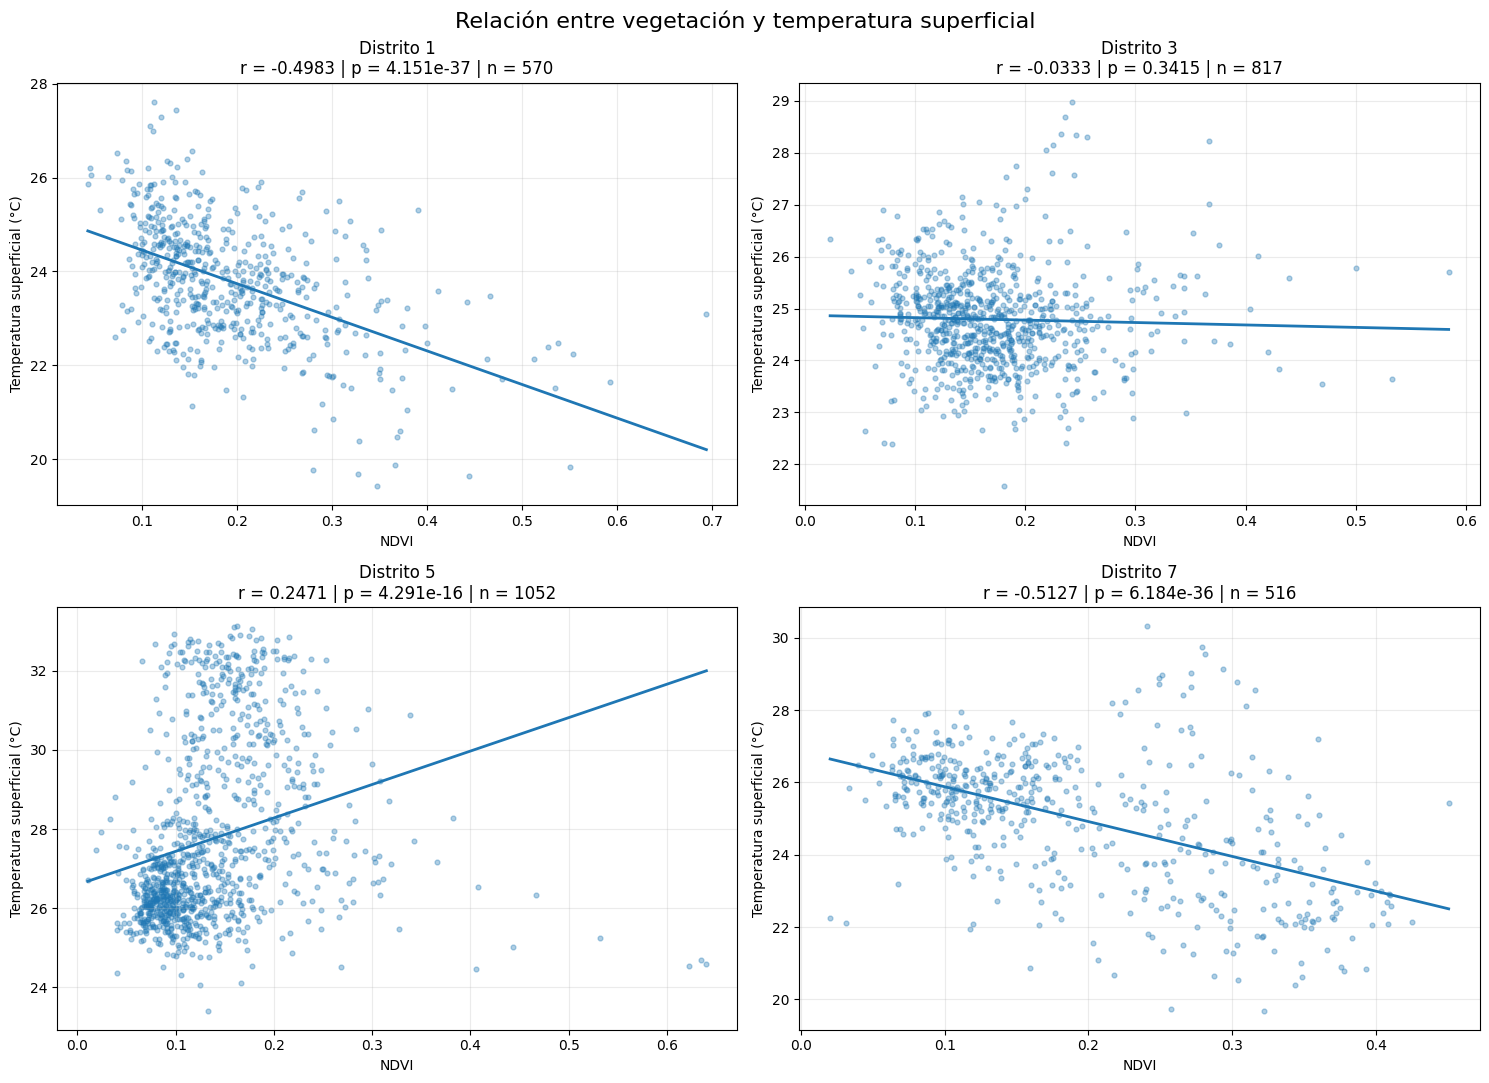

In [44]:

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr, linregress

# Orden de los distritos
distritos_graficos = [
    "Distrito 1",
    "Distrito 3",
    "Distrito 5",
    "Distrito 7"
]

# Crear una figura con cuatro gráficos
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, distrito in enumerate(distritos_graficos):

    # Filtrar datos del distrito
    datos = datos_muestras[
        datos_muestras["nombre"] == distrito
    ].dropna(subset=["NDVI", "LST_C"])

    x = datos["NDVI"].values
    y = datos["LST_C"].values

    # Correlación y regresión lineal
    r, p = pearsonr(x, y)
    regresion = linregress(x, y)

    # Gráfico de dispersión
    axes[i].scatter(
        x, y,
        alpha=0.35,
        s=12
    )

    # Línea de tendencia
    x_linea = np.linspace(x.min(), x.max(), 100)
    y_linea = regresion.slope * x_linea + regresion.intercept

    axes[i].plot(
        x_linea,
        y_linea,
        linewidth=2
    )

    axes[i].set_title(
        f"{distrito}\nr = {r:.4f} | p = {p:.4g} | n = {len(datos)}"
    )

    axes[i].set_xlabel("NDVI")
    axes[i].set_ylabel("Temperatura superficial (°C)")
    axes[i].grid(alpha=0.25)

plt.suptitle(
    "Relación entre vegetación y temperatura superficial",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [52]:

from statsmodels.stats.multitest import multipletests
import pandas as pd

# Copiar los resultados de las 15 correlaciones
resultados_fdr = datos_correlacion.copy()

# Aplicar corrección Benjamini-Hochberg
rechazo, p_ajustados, _, _ = multipletests(
    resultados_fdr["p-value"].astype(float),
    alpha=0.05,
    method="fdr_bh"
)

resultados_fdr["p_ajustado_FDR"] = p_ajustados
resultados_fdr["Significativo_FDR"] = rechazo

# Ordenar por distrito
resultados_fdr = resultados_fdr.sort_values(
    "codigo_distrito"
)

# Mostrar resultados
display(
    resultados_fdr[
        [
            "nombre",
            "correlation",
            "p-value",
            "p_ajustado_FDR",
            "Significativo_FDR"
        ]
    ].rename(columns={
        "correlation": "Pearson",
        "p-value": "Valor p original",
        "p_ajustado_FDR": "Valor p ajustado",
        "Significativo_FDR": "Significativo FDR"
    }).round(6)
)

print(
    "\nDistritos significativos después de FDR:",
    rechazo.sum(),
    "de",
    len(rechazo)
)


,nombre,Pearson,Valor p original,Valor p ajustado,Significativo FDR
0,Distrito 1,-0.498317,0.000000,0.000000,True
1,Distrito 10,-0.328383,0.000000,0.000000,True
2,Distrito 11,-0.376815,0.000000,0.000000,True
3,Distrito 12,-0.416533,0.000000,0.000000,True
4,Distrito 13,-0.473592,0.000000,0.000000,True
5,Distrito 14,-0.453943,0.000000,0.000000,True
6,Distrito 15,-0.193888,0.000000,0.000000,True
7,Distrito 2,-0.243417,0.000000,0.000000,True
8,Distrito 3,-0.033321,0.341492,0.341492,False
9,Distrito 4,-0.254319,0.000000,0.000000,True



Distritos significativos después de FDR: 13 de 15


In [46]:

# Guardar resultados de correlación y corrección FDR
ruta_correlaciones = "/content/correlaciones_ndvi_lst_fdr.csv"

resultados_fdr.to_csv(
    ruta_correlaciones,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo guardado correctamente:")
print(ruta_correlaciones)

# Comprobar el archivo
print("\nDimensiones:", resultados_fdr.shape)
print("Distritos analizados:", resultados_fdr["nombre"].nunique())


Archivo guardado correctamente:
/content/correlaciones_ndvi_lst_fdr.csv

Dimensiones: (15, 11)
Distritos analizados: 15


In [53]:

# Guardar resultados de correlación y corrección FDR
ruta_correlaciones = "/content/correlaciones_ndvi_lst_fdr.csv"

resultados_fdr.to_csv(
    ruta_correlaciones,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo guardado correctamente:")
print(ruta_correlaciones)

# Comprobar el archivo
print("\nDimensiones:", resultados_fdr.shape)
print("Distritos analizados:", resultados_fdr["nombre"].nunique())


Archivo guardado correctamente:
/content/correlaciones_ndvi_lst_fdr.csv

Dimensiones: (15, 11)
Distritos analizados: 15


In [55]:

print("Columnas de df_areas:")
print(df_areas.columns.tolist())

print("\nPrimeros registros:")
display(df_areas.head())

print("\nColumnas de df_ambiental:")
print(df_ambiental.columns.tolist())


Columnas de df_areas:
['codigo', 'codigo_distrito', 'fuente', 'latitud', 'longitud', 'municipio_ine', 'nombre', 'superficie_valida_ha', 'vegetacion_ha']

Primeros registros:


,codigo,codigo_distrito,fuente,latitud,longitud,municipio_ine,nombre,superficie_valida_ha,vegetacion_ha
0,030101-distrito-1,1,ciudatoslab,-17.367893,-66.127688,030101,Distrito 1,569.313720,62.408971
1,030101-distrito-10,10,ciudatoslab,-17.395909,-66.158294,030101,Distrito 10,559.989405,49.837467
2,030101-distrito-11,11,ciudatoslab,-17.386697,-66.140482,030101,Distrito 11,555.649077,150.352239
3,030101-distrito-12,12,ciudatoslab,-17.380088,-66.165810,030101,Distrito 12,765.248059,83.004857
4,030101-distrito-13,13,ciudatoslab,-17.323254,-66.151448,030101,Distrito 13,4878.200446,1941.437589



Columnas de df_ambiental:
['LST_C_max', 'LST_C_mean', 'LST_C_median', 'LST_C_min', 'LST_C_stdDev', 'NDVI_max', 'NDVI_mean', 'NDVI_median', 'NDVI_min', 'NDVI_stdDev', 'codigo', 'codigo_distrito', 'fuente', 'latitud', 'longitud', 'municipio_ine', 'nombre']


In [56]:

# 1. Seleccionar indicadores ambientales
columnas_ambientales = [
    "codigo_distrito",
    "nombre",
    "NDVI_mean",
    "NDVI_median",
    "NDVI_min",
    "NDVI_max",
    "LST_C_mean",
    "LST_C_median",
    "LST_C_min",
    "LST_C_max",
    "LST_C_stdDev"
]

tabla_ambiental = df_ambiental[columnas_ambientales].copy()

# 2. Seleccionar superficies
tabla_vegetacion = df_areas[
    [
        "codigo_distrito",
        "vegetacion_ha",
        "superficie_valida_ha"
    ]
].copy()

# 3. Calcular porcentaje de superficie con NDVI >= 0.3
tabla_vegetacion["porcentaje_vegetacion"] = (
    tabla_vegetacion["vegetacion_ha"]
    / tabla_vegetacion["superficie_valida_ha"]
) * 100

# 4. Incorporar indicadores de correlación y FDR
tabla_correlaciones = resultados_fdr[
    [
        "codigo_distrito",
        "correlation",
        "p-value",
        "p_ajustado_FDR",
        "Significativo_FDR"
    ]
].copy()

# 5. Unir todas las tablas
indicadores_distritales = (
    tabla_ambiental
    .merge(tabla_vegetacion, on="codigo_distrito")
    .merge(tabla_correlaciones, on="codigo_distrito")
)

# 6. Ordenar por número de distrito
indicadores_distritales = (
    indicadores_distritales
    .sort_values("codigo_distrito")
    .reset_index(drop=True)
)

# 7. Mostrar resultados
print("Distritos consolidados:", len(indicadores_distritales))
print("Indicadores disponibles:", len(indicadores_distritales.columns))

display(indicadores_distritales.round(4))


Distritos consolidados: 15
Indicadores disponibles: 18


,codigo_distrito,nombre,NDVI_mean,NDVI_median,NDVI_min,NDVI_max,LST_C_mean,LST_C_median,LST_C_min,LST_C_max,LST_C_stdDev,vegetacion_ha,superficie_valida_ha,porcentaje_vegetacion,correlation,p-value,p_ajustado_FDR,Significativo_FDR
0,1,Distrito 1,0.1920,0.1660,0.0223,0.6937,23.7840,23.7825,19.4230,27.6149,1.3199,62.4090,569.3137,10.9621,-0.4983,0.0000,0.0000,True
1,10,Distrito 10,0.1314,0.0986,-0.0018,0.4889,25.4642,25.4536,22.8787,30.1287,1.1764,49.8375,559.9894,8.8997,-0.3284,0.0000,0.0000,True
2,11,Distrito 11,0.2322,0.2366,0.0475,0.5804,25.0316,25.2860,20.0645,32.5461,1.9910,150.3522,555.6491,27.0588,-0.3768,0.0000,0.0000,True
3,12,Distrito 12,0.1828,0.1589,0.0367,0.4925,24.5542,24.6393,20.5940,27.6203,1.1638,83.0049,765.2481,10.8468,-0.4165,0.0000,0.0000,True
4,13,Distrito 13,0.3142,0.2675,-0.0953,0.8720,19.0085,18.5612,9.4542,34.2405,3.8434,1941.4376,4878.2004,39.7982,-0.4736,0.0000,0.0000,True
5,14,Distrito 14,0.1398,0.1342,0.0342,0.3927,24.6262,25.0268,18.2675,30.6518,2.3829,4.1192,693.6825,0.5938,-0.4539,0.0000,0.0000,True
6,15,Distrito 15,0.1673,0.1580,0.0423,0.5927,29.1292,29.2092,20.9021,35.3370,2.3342,38.6553,2121.9851,1.8217,-0.1939,0.0000,0.0000,True
7,2,Distrito 2,0.1808,0.1669,0.0626,0.4542,23.6163,23.6407,20.3964,26.9306,0.9853,59.6955,907.0544,6.5812,-0.2434,0.0000,0.0000,True
8,3,Distrito 3,0.1710,0.1582,0.0229,0.6508,24.7844,24.7695,21.5761,28.9827,0.9668,36.9486,815.5416,4.5306,-0.0333,0.3415,0.3415,False
9,4,Distrito 4,0.1473,0.1232,0.0276,0.6653,25.5065,25.5999,19.8368,30.3900,1.1386,46.3586,833.8687,5.5595,-0.2543,0.0000,0.0000,True


In [57]:

# 1. Seleccionar indicadores ambientales
columnas_ambientales = [
    "codigo_distrito",
    "nombre",
    "NDVI_mean",
    "NDVI_median",
    "NDVI_min",
    "NDVI_max",
    "LST_C_mean",
    "LST_C_median",
    "LST_C_min",
    "LST_C_max",
    "LST_C_stdDev"
]

tabla_ambiental = df_ambiental[columnas_ambientales].copy()

# 2. Seleccionar superficies
tabla_vegetacion = df_areas[
    [
        "codigo_distrito",
        "vegetacion_ha",
        "superficie_valida_ha"
    ]
].copy()

# 3. Calcular porcentaje de superficie con NDVI >= 0.3
tabla_vegetacion["porcentaje_vegetacion"] = (
    tabla_vegetacion["vegetacion_ha"]
    / tabla_vegetacion["superficie_valida_ha"]
) * 100

# 4. Incorporar indicadores de correlación y FDR
tabla_correlaciones = resultados_fdr[
    [
        "codigo_distrito",
        "correlation",
        "p-value",
        "p_ajustado_FDR",
        "Significativo_FDR"
    ]
].copy()

# 5. Unir todas las tablas
indicadores_distritales = (
    tabla_ambiental
    .merge(tabla_vegetacion, on="codigo_distrito")
    .merge(tabla_correlaciones, on="codigo_distrito")
)

# 6. Ordenar por número de distrito
indicadores_distritales = (
    indicadores_distritales
    .sort_values("codigo_distrito")
    .reset_index(drop=True)
)

# 7. Mostrar resultados
print("Distritos consolidados:", len(indicadores_distritales))
print("Indicadores disponibles:", len(indicadores_distritales.columns))

display(indicadores_distritales.round(4))


Distritos consolidados: 15
Indicadores disponibles: 18


,codigo_distrito,nombre,NDVI_mean,NDVI_median,NDVI_min,NDVI_max,LST_C_mean,LST_C_median,LST_C_min,LST_C_max,LST_C_stdDev,vegetacion_ha,superficie_valida_ha,porcentaje_vegetacion,correlation,p-value,p_ajustado_FDR,Significativo_FDR
0,1,Distrito 1,0.1920,0.1660,0.0223,0.6937,23.7840,23.7825,19.4230,27.6149,1.3199,62.4090,569.3137,10.9621,-0.4983,0.0000,0.0000,True
1,10,Distrito 10,0.1314,0.0986,-0.0018,0.4889,25.4642,25.4536,22.8787,30.1287,1.1764,49.8375,559.9894,8.8997,-0.3284,0.0000,0.0000,True
2,11,Distrito 11,0.2322,0.2366,0.0475,0.5804,25.0316,25.2860,20.0645,32.5461,1.9910,150.3522,555.6491,27.0588,-0.3768,0.0000,0.0000,True
3,12,Distrito 12,0.1828,0.1589,0.0367,0.4925,24.5542,24.6393,20.5940,27.6203,1.1638,83.0049,765.2481,10.8468,-0.4165,0.0000,0.0000,True
4,13,Distrito 13,0.3142,0.2675,-0.0953,0.8720,19.0085,18.5612,9.4542,34.2405,3.8434,1941.4376,4878.2004,39.7982,-0.4736,0.0000,0.0000,True
5,14,Distrito 14,0.1398,0.1342,0.0342,0.3927,24.6262,25.0268,18.2675,30.6518,2.3829,4.1192,693.6825,0.5938,-0.4539,0.0000,0.0000,True
6,15,Distrito 15,0.1673,0.1580,0.0423,0.5927,29.1292,29.2092,20.9021,35.3370,2.3342,38.6553,2121.9851,1.8217,-0.1939,0.0000,0.0000,True
7,2,Distrito 2,0.1808,0.1669,0.0626,0.4542,23.6163,23.6407,20.3964,26.9306,0.9853,59.6955,907.0544,6.5812,-0.2434,0.0000,0.0000,True
8,3,Distrito 3,0.1710,0.1582,0.0229,0.6508,24.7844,24.7695,21.5761,28.9827,0.9668,36.9486,815.5416,4.5306,-0.0333,0.3415,0.3415,False
9,4,Distrito 4,0.1473,0.1232,0.0276,0.6653,25.5065,25.5999,19.8368,30.3900,1.1386,46.3586,833.8687,5.5595,-0.2543,0.0000,0.0000,True


In [58]:

# Exportar tabla maestra de indicadores
ruta_maestra = "/content/indicadores_ambientales_distritos.csv"

indicadores_distritales.to_csv(
    ruta_maestra,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo exportado:", ruta_maestra)
print("Total de distritos:", len(indicadores_distritales))
print("Total de indicadores:", len(indicadores_distritales.columns))

# Verificar que el archivo se pueda leer
verificacion = pd.read_csv(ruta_maestra)

print("\nVerificación:")
print(verificacion.shape)
display(verificacion.head())


Archivo exportado: /content/indicadores_ambientales_distritos.csv
Total de distritos: 15
Total de indicadores: 18

Verificación:
(15, 18)


,codigo_distrito,nombre,NDVI_mean,NDVI_median,NDVI_min,NDVI_max,LST_C_mean,LST_C_median,LST_C_min,LST_C_max,LST_C_stdDev,vegetacion_ha,superficie_valida_ha,porcentaje_vegetacion,correlation,p-value,p_ajustado_FDR,Significativo_FDR
0,1,Distrito 1,0.191978,0.166042,0.022259,0.693651,23.783990,23.782546,19.422973,27.614864,1.319922,62.408971,569.313720,10.962141,-0.498317,4.151235e-37,1.556713e-36,True
1,10,Distrito 10,0.131357,0.098562,-0.001849,0.488923,25.464174,25.453603,22.878662,30.128741,1.176420,49.837467,559.989405,8.899716,-0.328383,1.908119e-15,2.601980e-15,True
2,11,Distrito 11,0.232161,0.236590,0.047511,0.580378,25.031553,25.286011,20.064467,32.546103,1.990981,150.352239,555.649077,27.058848,-0.376815,2.112784e-20,3.961470e-20,True
3,12,Distrito 12,0.182755,0.158931,0.036705,0.492495,24.554208,24.639296,20.594004,27.620308,1.163797,83.004857,765.248059,10.846791,-0.416533,1.143114e-33,2.449530e-33,True
4,13,Distrito 13,0.314184,0.267541,-0.095326,0.871956,19.008505,18.561176,9.454249,34.240500,3.843351,1941.437589,4878.200446,39.798233,-0.473592,2.599214e-271,1.949411e-270,True


In [59]:

import geopandas as gpd
import pandas as pd

# 1. Copiar los límites distritales originales
distritos_plataforma = cochabamba_distritos.copy()

# 2. Asegurar que el código sea numérico para unir las tablas
distritos_plataforma["codigo_distrito"] = (
    distritos_plataforma["codigo_distrito"].astype(int)
)

indicadores_distritales["codigo_distrito"] = (
    indicadores_distritales["codigo_distrito"].astype(int)
)

# 3. Incorporar los indicadores ambientales
distritos_plataforma = distritos_plataforma.merge(
    indicadores_distritales,
    on=["codigo_distrito", "nombre"],
    how="left",
    validate="one_to_one"
)

# 4. Verificar que todos los distritos tengan indicadores
print("Total de distritos:", len(distritos_plataforma))
print(
    "Distritos sin indicadores:",
    distritos_plataforma["NDVI_mean"].isna().sum()
)

# 5. Exportar en coordenadas geográficas WGS84
distritos_plataforma = distritos_plataforma.to_crs("EPSG:4326")

ruta_geojson = "/content/distritos_indicadores_cochabamba.geojson"

distritos_plataforma.to_file(
    ruta_geojson,
    driver="GeoJSON"
)

print("\nGeoJSON generado correctamente:")
print(ruta_geojson)

# 6. Revisar atributos disponibles
print("\nColumnas del GeoJSON:")
print(distritos_plataforma.columns.tolist())

display(
    distritos_plataforma[
        ["nombre", "NDVI_mean", "LST_C_mean", "correlation", "geometry"]
    ].head()
)


Total de distritos: 15
Distritos sin indicadores: 0

GeoJSON generado correctamente:
/content/distritos_indicadores_cochabamba.geojson

Columnas del GeoJSON:
['codigo', 'municipio_ine', 'codigo_distrito', 'nombre', 'fuente', 'latitud', 'longitud', 'geometry', 'NDVI_mean', 'NDVI_median', 'NDVI_min', 'NDVI_max', 'LST_C_mean', 'LST_C_median', 'LST_C_min', 'LST_C_max', 'LST_C_stdDev', 'vegetacion_ha', 'superficie_valida_ha', 'porcentaje_vegetacion', 'correlation', 'p-value', 'p_ajustado_FDR', 'Significativo_FDR']


,nombre,NDVI_mean,LST_C_mean,correlation,geometry
0,Distrito 1,0.191978,23.783990,-0.498317,"MULTIPOLYGON (((-66.13522 -17.37413, -66.13495..."
1,Distrito 10,0.131357,25.464174,-0.328383,"MULTIPOLYGON (((-66.14826 -17.39987, -66.14836..."
2,Distrito 11,0.232161,25.031553,-0.376815,"MULTIPOLYGON (((-66.12778 -17.39602, -66.12731..."
3,Distrito 12,0.182755,24.554208,-0.416533,"MULTIPOLYGON (((-66.1496 -17.36698, -66.15475 ..."
4,Distrito 13,0.314184,19.008505,-0.473592,"MULTIPOLYGON (((-66.13119 -17.36299, -66.1276 ..."


In [60]:

import pandas as pd

# Obtener las escenas Landsat utilizadas
lista_escenas = lst_coleccion.toList(lst_coleccion.size())
total_escenas = lst_coleccion.size().getInfo()

registros_proyeccion = []

for i in range(total_escenas):
    imagen = ee.Image(lista_escenas.get(i))

    # Información de la banda térmica original
    proyeccion = imagen.select("LST_C").projection().getInfo()
    propiedades = imagen.toDictionary([
        "system:time_start",
        "SPACECRAFT_ID",
        "WRS_PATH",
        "WRS_ROW"
    ]).getInfo()

    registros_proyeccion.append({
        "fecha": pd.to_datetime(
            propiedades.get("system:time_start"),
            unit="ms"
        ).strftime("%Y-%m-%d"),
        "satelite": propiedades.get("SPACECRAFT_ID"),
        "path": propiedades.get("WRS_PATH"),
        "row": propiedades.get("WRS_ROW"),
        "CRS": proyeccion.get("crs"),
        "escala_x": proyeccion.get("transform", [None])[0],
        "escala_y": proyeccion.get("transform", [None])[4]
    })

df_proyecciones = pd.DataFrame(registros_proyeccion)

print("Total de escenas:", len(df_proyecciones))
print("\nEscenas agrupadas por proyección:")
display(
    df_proyecciones.groupby(["satelite", "CRS"]).size()
    .reset_index(name="cantidad")
)

print("\nDetalle de las escenas:")
display(df_proyecciones)


Total de escenas: 22

Escenas agrupadas por proyección:


,satelite,CRS,cantidad
0,LANDSAT_8,EPSG:32719,5
1,LANDSAT_8,EPSG:32720,6
2,LANDSAT_9,EPSG:32619,6
3,LANDSAT_9,EPSG:32620,5



Detalle de las escenas:


,fecha,satelite,path,row,CRS,escala_x,escala_y
0,2024-06-06,LANDSAT_8,None,None,EPSG:32720,30,-30
1,2024-06-22,LANDSAT_8,None,None,EPSG:32720,30,-30
2,2024-07-08,LANDSAT_8,None,None,EPSG:32720,30,-30
3,2024-07-24,LANDSAT_8,None,None,EPSG:32720,30,-30
4,2024-08-09,LANDSAT_8,None,None,EPSG:32720,30,-30
5,2024-08-25,LANDSAT_8,None,None,EPSG:32720,30,-30
6,2024-06-13,LANDSAT_8,None,None,EPSG:32719,30,-30
7,2024-06-29,LANDSAT_8,None,None,EPSG:32719,30,-30
8,2024-07-15,LANDSAT_8,None,None,EPSG:32719,30,-30
9,2024-07-31,LANDSAT_8,None,None,EPSG:32719,30,-30


In [61]:

import ee
import pandas as pd

lista_escenas = lst_coleccion.toList(lst_coleccion.size())
total_escenas = lst_coleccion.size().getInfo()

geometria_distritos = distritos_ee.geometry()

registros_ubicacion = []

for i in range(total_escenas):
    imagen = ee.Image(lista_escenas.get(i))

    centro = imagen.geometry().centroid(100).coordinates().getInfo()

    propiedades = imagen.toDictionary([
        "system:index",
        "system:time_start",
        "SPACECRAFT_ID",
        "WRS_PATH",
        "WRS_ROW"
    ]).getInfo()

    proyeccion = imagen.select("LST_C").projection().getInfo()

    intersecta = imagen.geometry().intersects(
        geometria_distritos,
        ee.ErrorMargin(100)
    ).getInfo()

    registros_ubicacion.append({
        "fecha": pd.to_datetime(
            propiedades.get("system:time_start"),
            unit="ms"
        ).strftime("%Y-%m-%d"),
        "escena": propiedades.get("system:index"),
        "satelite": propiedades.get("SPACECRAFT_ID"),
        "CRS": proyeccion.get("crs"),
        "longitud_centro": centro[0],
        "latitud_centro": centro[1],
        "intersecta_Cochabamba": intersecta
    })

df_ubicacion = pd.DataFrame(registros_ubicacion)

display(df_ubicacion)

print("\nResumen por proyección:")
display(
    df_ubicacion.groupby(
        ["satelite", "CRS", "intersecta_Cochabamba"]
    ).size().reset_index(name="cantidad")
)

print(
    "\nEscenas que intersectan los distritos:",
    df_ubicacion["intersecta_Cochabamba"].sum(),
    "de",
    total_escenas
)


,fecha,escena,satelite,CRS,longitud_centro,latitud_centro,intersecta_Cochabamba
0,2024-06-06,1_LC08_232072_20240606,LANDSAT_8,EPSG:32720,-65.273942,-17.345994,True
1,2024-06-22,1_LC08_232072_20240622,LANDSAT_8,EPSG:32720,-65.273302,-17.345856,True
2,2024-07-08,1_LC08_232072_20240708,LANDSAT_8,EPSG:32720,-65.270273,-17.345550,True
3,2024-07-24,1_LC08_232072_20240724,LANDSAT_8,EPSG:32720,-65.293704,-17.346155,True
4,2024-08-09,1_LC08_232072_20240809,LANDSAT_8,EPSG:32720,-65.248831,-17.346676,True
5,2024-08-25,1_LC08_232072_20240825,LANDSAT_8,EPSG:32720,-65.268114,-17.345518,True
6,2024-06-13,1_LC08_233072_20240613,LANDSAT_8,EPSG:32719,-66.801410,-17.345676,True
7,2024-06-29,1_LC08_233072_20240629,LANDSAT_8,EPSG:32719,-66.813027,-17.346103,True
8,2024-07-15,1_LC08_233072_20240715,LANDSAT_8,EPSG:32719,-66.827236,-17.345716,True
9,2024-07-31,1_LC08_233072_20240731,LANDSAT_8,EPSG:32719,-66.824973,-17.345867,True



Resumen por proyección:


,satelite,CRS,intersecta_Cochabamba,cantidad
0,LANDSAT_8,EPSG:32719,True,5
1,LANDSAT_8,EPSG:32720,True,6
2,LANDSAT_9,EPSG:32619,True,6
3,LANDSAT_9,EPSG:32620,True,5



Escenas que intersectan los distritos: 22 de 22


In [62]:

import ee
import pandas as pd

# Elegir una escena representativa de cada CRS
crs_revisar = [
    "EPSG:32719",
    "EPSG:32720",
    "EPSG:32619",
    "EPSG:32620"
]

registros_transformacion = []

for crs in crs_revisar:

    escena = df_ubicacion[df_ubicacion["CRS"] == crs].iloc[0]
    imagen = ee.Image(
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
        .filter(ee.Filter.eq("system:index", escena["escena"]))
        .first()
    )

    proy = imagen.select("ST_B10").projection().getInfo()

    registros_transformacion.append({
        "escena": escena["escena"],
        "CRS": proy["crs"],
        "transformacion": str(proy["transform"]),
        "escala_nominal_m": imagen.select("ST_B10")
            .projection().nominalScale().getInfo(),
        "centro_longitud": escena["longitud_centro"],
        "centro_latitud": escena["latitud_centro"]
    })

df_transformaciones = pd.DataFrame(registros_transformacion)

display(df_transformaciones)


,escena,CRS,transformacion,escala_nominal_m,centro_longitud,centro_latitud
0,1_LC08_233072_20240613,EPSG:32719,"[30, 0, 618585, 0, -30, 8197915]",30,-66.801410,-17.345676
1,1_LC08_232072_20240606,EPSG:32720,"[30, 0, 144885, 0, -30, 8196115]",30,-65.273942,-17.345994
2,2_LC09_233072_20240605,EPSG:32619,"[30, 0, 616785, 0, -30, -1802385]",30,-66.810344,-17.347125
3,2_LC09_232072_20240614,EPSG:32620,"[30, 0, 146085, 0, -30, -1803885]",30,-65.256540,-17.347187


In [64]:
for nombre in [
    "lst_coleccion",
    "lst_median_corregida",
    "geometria_distritos",
    "distritos_ee",
    "ee",
    "pd"
]:
    print(f"{nombre}: {'Disponible' if nombre in globals() else 'No disponible'}")

lst_coleccion: Disponible
lst_median_corregida: No disponible
geometria_distritos: Disponible
distritos_ee: Disponible
ee: Disponible
pd: Disponible


In [66]:
# Reconstruir LST corregida con la metodología original
lst_median_corregida = (
    lst_coleccion
    .median()
    .reproject(
        crs=ee.Projection("EPSG:32719").atScale(30)
    )
    .clip(geometria_distritos)
)

# Calcular estadísticas por distrito
validacion_lst = lst_median_corregida.reduceRegions(
    collection=distritos_ee,
    reducer=(
        ee.Reducer.mean()
        .combine(ee.Reducer.minMax(), sharedInputs=True)
        .combine(ee.Reducer.count(), sharedInputs=True)
    ),
    scale=30,
    crs="EPSG:32719",
    tileScale=4
)

# Convertir resultados a DataFrame
datos_validacion_lst = pd.DataFrame([
    feature["properties"]
    for feature in validacion_lst.getInfo()["features"]
])

print("Validación LST reconstruida:")
display(datos_validacion_lst.head())

Validación LST reconstruida:


,codigo,codigo_distrito,count,fuente,latitud,longitud,max,mean,min,municipio_ine,nombre
0,030101-distrito-1,1,6572,ciudatoslab,-17.367893,-66.127688,27.739973,23.784949,18.842867,030101,Distrito 1
1,030101-distrito-10,10,6429,ciudatoslab,-17.395909,-66.158294,30.901641,25.459555,21.888323,030101,Distrito 10
2,030101-distrito-11,11,6400,ciudatoslab,-17.386697,-66.140482,33.253239,25.037556,19.543561,030101,Distrito 11
3,030101-distrito-12,12,8776,ciudatoslab,-17.380088,-66.165810,27.408425,24.555188,19.543561,030101,Distrito 12
4,030101-distrito-13,13,54879,ciudatoslab,-17.323254,-66.151448,35.145113,19.008245,8.855412,030101,Distrito 13


In [67]:

# 1. Definir la proyección de salida
proyeccion_100m = ee.Projection("EPSG:32719").atScale(100)

# 2. Agregar la temperatura superficial a 100 m
lst_100m_final = (
    lst_median_corregida
    .reduceResolution(
        reducer=ee.Reducer.mean(),
        maxPixels=1024
    )
    .reproject(crs=proyeccion_100m)
    .rename("LST_C")
    .clip(geometria_distritos)
)

# 3. Consultar las características del raster
print("Proyección:")
print(lst_100m_final.projection().getInfo())

print("\nResolución nominal:")
print(lst_100m_final.projection().nominalScale().getInfo(), "metros")

# 4. Revisar estadísticas generales
estadisticas_lst_100m = lst_100m_final.reduceRegion(
    reducer=ee.Reducer.minMax().combine(
        ee.Reducer.mean(),
        sharedInputs=True
    ),
    geometry=geometria_distritos,
    scale=100,
    crs="EPSG:32719",
    maxPixels=1e13,
    tileScale=4
).getInfo()

print("\nEstadísticas del raster térmico de 100 m:")
print(estadisticas_lst_100m)


Proyección:
{'type': 'Projection', 'crs': 'EPSG:32719', 'transform': [100, 0, 0, 0, 100, 0]}

Resolución nominal:
100 metros

Estadísticas del raster térmico de 100 m:
{'LST_C_max': 35.979144150200305, 'LST_C_mean': 25.273389967119382, 'LST_C_min': 9.454249364004939}


In [68]:

# Crear tarea de exportación a Google Drive
tarea_lst = ee.batch.Export.image.toDrive(
    image=lst_100m_final,
    description="LST_Cochabamba_2024_100m",
    folder="Microclimas_Cochabamba",
    fileNamePrefix="lst_cochabamba_2024_100m",
    region=geometria_distritos,
    crs="EPSG:32719",
    scale=100,
    maxPixels=1e13,
    fileFormat="GeoTIFF"
)

# Iniciar exportación
tarea_lst.start()

print("Estado de la tarea:")
print(tarea_lst.status())


Estado de la tarea:
{'state': 'READY', 'description': 'LST_Cochabamba_2024_100m', 'priority': 100, 'creation_timestamp_ms': 1794350216983, 'update_timestamp_ms': 1794350216983, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'PDHOWTUJR25PJNX76LLURCZP', 'name': 'projects/microclimas-cochabamba/operations/PDHOWTUJR25PJNX76LLURCZP'}


In [69]:
print(tarea_lst.status())

{'state': 'READY', 'description': 'LST_Cochabamba_2024_100m', 'priority': 100, 'creation_timestamp_ms': 1794350216983, 'update_timestamp_ms': 1794350216983, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'PDHOWTUJR25PJNX76LLURCZP', 'name': 'projects/microclimas-cochabamba/operations/PDHOWTUJR25PJNX76LLURCZP'}


In [70]:

# 1. Definir la misma cuadrícula de trabajo del raster térmico
proyeccion_100m = ee.Projection("EPSG:32719").atScale(100)

# 2. Agregar el NDVI de 10 m a 100 m
ndvi_100m_final = (
    ndvi_con_proyeccion
    .reduceResolution(
        reducer=ee.Reducer.mean(),
        maxPixels=1024
    )
    .reproject(crs=proyeccion_100m)
    .rename("NDVI")
    .clip(geometria_distritos)
)

# 3. Revisar proyección y resolución
print("Proyección:")
print(ndvi_100m_final.projection().getInfo())

print("\nResolución nominal:")
print(ndvi_100m_final.projection().nominalScale().getInfo(), "metros")

# 4. Calcular estadísticas generales
estadisticas_ndvi_100m = ndvi_100m_final.reduceRegion(
    reducer=ee.Reducer.minMax().combine(
        ee.Reducer.mean(),
        sharedInputs=True
    ),
    geometry=geometria_distritos,
    scale=100,
    crs="EPSG:32719",
    maxPixels=1e13,
    tileScale=4
).getInfo()

print("\nEstadísticas del raster NDVI de 100 m:")
print(estadisticas_ndvi_100m)


Proyección:
{'type': 'Projection', 'crs': 'EPSG:32719', 'transform': [100, 0, 0, 0, 100, 0]}

Resolución nominal:
100 metros

Estadísticas del raster NDVI de 100 m:
{'NDVI_max': 0.8719556331634521, 'NDVI_mean': 0.22192411169663395, 'NDVI_min': -0.6933801770210266}


In [71]:
print(tarea_lst.status())

{'state': 'COMPLETED', 'description': 'LST_Cochabamba_2024_100m', 'priority': 100, 'creation_timestamp_ms': 1794350216983, 'update_timestamp_ms': 1794350267381, 'start_timestamp_ms': 1794350220080, 'task_type': 'EXPORT_IMAGE', 'destination_uris': ['https://drive.google.com/#folders/1wgGbDtsJxIQBW_IeDMMeW-M8kn4ketUD'], 'attempt': 1, 'batch_eecu_usage_seconds': 28.418331146240234, 'id': 'PDHOWTUJR25PJNX76LLURCZP', 'name': 'projects/microclimas-cochabamba/operations/PDHOWTUJR25PJNX76LLURCZP'}


In [72]:
# Exportar NDVI de Cochabamba a Google Drive
tarea_ndvi = ee.batch.Export.image.toDrive(
    image=ndvi_100m_final,
    description="NDVI_Cochabamba_2024_100m",
    folder="Microclimas_Cochabamba",
    fileNamePrefix="ndvi_cochabamba_2024_100m",
    region=geometria_distritos,
    crs="EPSG:32719",
    scale=100,
    maxPixels=1e13,
    fileFormat="GeoTIFF"
)

tarea_ndvi.start()

print("Estado de exportación NDVI:")
print(tarea_ndvi.status())

Estado de exportación NDVI:
{'state': 'READY', 'description': 'NDVI_Cochabamba_2024_100m', 'priority': 100, 'creation_timestamp_ms': 1794350380637, 'update_timestamp_ms': 1794350380637, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': '3CH67QMB4CNOR4DDZK6UAOAE', 'name': 'projects/microclimas-cochabamba/operations/3CH67QMB4CNOR4DDZK6UAOAE'}


In [73]:
print("ESTADO DE EXPORTACIONES")
print("-" * 40)

print("LST:")
print(tarea_lst.status())

print("\nNDVI:")
print(tarea_ndvi.status())

ESTADO DE EXPORTACIONES
----------------------------------------
LST:
{'state': 'COMPLETED', 'description': 'LST_Cochabamba_2024_100m', 'priority': 100, 'creation_timestamp_ms': 1794350216983, 'update_timestamp_ms': 1794350267381, 'start_timestamp_ms': 1794350220080, 'task_type': 'EXPORT_IMAGE', 'destination_uris': ['https://drive.google.com/#folders/1wgGbDtsJxIQBW_IeDMMeW-M8kn4ketUD'], 'attempt': 1, 'batch_eecu_usage_seconds': 28.418331146240234, 'id': 'PDHOWTUJR25PJNX76LLURCZP', 'name': 'projects/microclimas-cochabamba/operations/PDHOWTUJR25PJNX76LLURCZP'}

NDVI:
{'state': 'RUNNING', 'description': 'NDVI_Cochabamba_2024_100m', 'priority': 100, 'creation_timestamp_ms': 1794350380637, 'update_timestamp_ms': 1794350383617, 'start_timestamp_ms': 1794350383554, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'id': '3CH67QMB4CNOR4DDZK6UAOAE', 'name': 'projects/microclimas-cochabamba/operations/3CH67QMB4CNOR4DDZK6UAOAE'}


In [74]:
print(tarea_ndvi.status())

{'state': 'RUNNING', 'description': 'NDVI_Cochabamba_2024_100m', 'priority': 100, 'creation_timestamp_ms': 1794350380637, 'update_timestamp_ms': 1794350383617, 'start_timestamp_ms': 1794350383554, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'id': '3CH67QMB4CNOR4DDZK6UAOAE', 'name': 'projects/microclimas-cochabamba/operations/3CH67QMB4CNOR4DDZK6UAOAE'}


In [75]:
import os
import rasterio
import numpy as np

print("Librerías preparadas.")
print("Rasterio:", rasterio.__version__)
print("Carpeta de trabajo:", os.getcwd())

Librerías preparadas.
Rasterio: 1.5.2
Carpeta de trabajo: /content


In [76]:
print(tarea_ndvi.status())

{'state': 'RUNNING', 'description': 'NDVI_Cochabamba_2024_100m', 'priority': 100, 'creation_timestamp_ms': 1794350380637, 'update_timestamp_ms': 1794350383617, 'start_timestamp_ms': 1794350383554, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'id': '3CH67QMB4CNOR4DDZK6UAOAE', 'name': 'projects/microclimas-cochabamba/operations/3CH67QMB4CNOR4DDZK6UAOAE'}


In [77]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [78]:
import os

carpeta = "/content/drive/MyDrive/Microclimas_Cochabamba"

print("Archivos encontrados:")
for archivo in os.listdir(carpeta):
    print(archivo)

Archivos encontrados:
lst_cochabamba_2024_100m.tif
ndvi_cochabamba_2024_100m.tif


In [79]:
import rasterio
import os

carpeta = "/content/drive/MyDrive/Microclimas_Cochabamba"

archivos = {
    "LST": os.path.join(carpeta, "lst_cochabamba_2024_100m.tif"),
    "NDVI": os.path.join(carpeta, "ndvi_cochabamba_2024_100m.tif")
}

for nombre, ruta in archivos.items():
    with rasterio.open(ruta) as src:
        print(f"\n{'='*45}")
        print(nombre)
        print("="*45)
        print("CRS:", src.crs)
        print("Resolución:", src.res)
        print("Dimensiones:", src.width, "x", src.height)
        print("Bandas:", src.count)
        print("Transformación:", src.transform)
        print("NoData:", src.nodata)
        print("Extensión:", src.bounds)


LST
CRS: EPSG:32719
Resolución: (100.0, 100.0)
Dimensiones: 227 x 284
Bandas: 1
Transformación: | 100.00, 0.00, 788800.00|
| 0.00,-100.00, 8087500.00|
| 0.00, 0.00, 1.00|
NoData: None
Extensión: BoundingBox(left=788800.0, bottom=8059100.0, right=811500.0, top=8087500.0)

NDVI
CRS: EPSG:32719
Resolución: (100.0, 100.0)
Dimensiones: 227 x 284
Bandas: 1
Transformación: | 100.00, 0.00, 788800.00|
| 0.00,-100.00, 8087500.00|
| 0.00, 0.00, 1.00|
NoData: None
Extensión: BoundingBox(left=788800.0, bottom=8059100.0, right=811500.0, top=8087500.0)


In [80]:
import numpy as np
import rasterio

for nombre, ruta in archivos.items():
    with rasterio.open(ruta) as src:
        datos = src.read(1)

        print(f"\n{'='*40}")
        print(nombre)
        print("="*40)
        print("Tipo de dato:", datos.dtype)
        print("Mínimo:", np.nanmin(datos))
        print("Máximo:", np.nanmax(datos))
        print("Media:", np.nanmean(datos))
        print("Píxeles totales:", datos.size)
        print("Píxeles NaN:", np.isnan(datos).sum())
        print("Píxeles iguales a cero:", np.sum(datos == 0))
        print("Píxeles enmascarados:", np.sum(src.read_masks(1) == 0))


LST
Tipo de dato: float64
Mínimo: 9.454249364004939
Máximo: 35.979144150200305
Media: 25.26834768384913
Píxeles totales: 64468
Píxeles NaN: 34430
Píxeles iguales a cero: 0
Píxeles enmascarados: 0

NDVI
Tipo de dato: float32
Mínimo: -0.6933802
Máximo: 0.87195563
Media: 0.22213005
Píxeles totales: 64468
Píxeles NaN: 34430
Píxeles iguales a cero: 0
Píxeles enmascarados: 0


In [81]:
with rasterio.open(archivos["LST"]) as src:
    lst = src.read(1)

with rasterio.open(archivos["NDVI"]) as src:
    ndvi = src.read(1)

# Máscara de píxeles válidos en ambos productos
mascara_valida = np.isfinite(lst) & np.isfinite(ndvi)

# Extraer valores correspondientes
lst_valido = lst[mascara_valida]
ndvi_valido = ndvi[mascara_valida]

print("Píxeles válidos compartidos:", len(lst_valido))
print("LST válida:", np.isfinite(lst_valido).all())
print("NDVI válido:", np.isfinite(ndvi_valido).all())

print("\nEstadísticas con máscara común:")
print("LST media:", np.mean(lst_valido))
print("NDVI medio:", np.mean(ndvi_valido))
print("Correlación Pearson:", np.corrcoef(ndvi_valido, lst_valido)[0, 1])

Píxeles válidos compartidos: 30038
LST válida: True
NDVI válido: True

Estadísticas con máscara común:
LST media: 25.26834768384913
NDVI medio: 0.22213006
Correlación Pearson: -0.41289063384392366


In [82]:
print("Distritos:", len(cochabamba_distritos))
print("CRS:", cochabamba_distritos.crs)
print("Geometrías nulas:", cochabamba_distritos.geometry.isna().sum())
print("Geometrías vacías:", cochabamba_distritos.geometry.is_empty.sum())

display(cochabamba_distritos[["nombre", "geometry"]].head())

Distritos: 15
CRS: EPSG:4326
Geometrías nulas: 0
Geometrías vacías: 0


,nombre,geometry
27,Distrito 1,"MULTIPOLYGON (((-66.13522 -17.37413, -66.13495..."
28,Distrito 10,"MULTIPOLYGON (((-66.14826 -17.39987, -66.14836..."
29,Distrito 11,"MULTIPOLYGON (((-66.12778 -17.39602, -66.12731..."
30,Distrito 12,"MULTIPOLYGON (((-66.1496 -17.36698, -66.15475 ..."
31,Distrito 13,"MULTIPOLYGON (((-66.13119 -17.36299, -66.1276 ..."


In [83]:
import geopandas as gpd
import rasterio
import numpy as np
import pandas as pd
from rasterio.features import geometry_mask

# Abrir los dos rásteres finales
with rasterio.open(archivos["LST"]) as src_lst, \
     rasterio.open(archivos["NDVI"]) as src_ndvi:

    # Verificar que ambos rásteres estén alineados
    assert src_lst.crs == src_ndvi.crs
    assert src_lst.transform == src_ndvi.transform
    assert src_lst.shape == src_ndvi.shape

    lst = src_lst.read(1)
    ndvi = src_ndvi.read(1)
    transformacion = src_lst.transform
    crs_raster = src_lst.crs

# Convertir distritos al CRS de los rásteres
distritos_metricos = cochabamba_distritos.to_crs(crs_raster)

resultados = []

for _, distrito in distritos_metricos.iterrows():

    # Máscara territorial del distrito
    mascara = geometry_mask(
        [distrito.geometry],
        out_shape=lst.shape,
        transform=transformacion,
        invert=True
    )

    # Píxeles válidos en ambos productos dentro del distrito
    validos = mascara & np.isfinite(lst) & np.isfinite(ndvi)

    lst_d = lst[validos]
    ndvi_d = ndvi[validos]

    if len(lst_d) == 0:
        continue

    resultados.append({
        "nombre": distrito["nombre"],
        "LST_C_mean": np.mean(lst_d),
        "LST_C_median": np.median(lst_d),
        "LST_C_min": np.min(lst_d),
        "LST_C_max": np.max(lst_d),
        "LST_C_stdDev": np.std(lst_d),
        "NDVI_mean": np.mean(ndvi_d),
        "NDVI_median": np.median(ndvi_d),
        "NDVI_min": np.min(ndvi_d),
        "NDVI_max": np.max(ndvi_d),
        "NDVI_stdDev": np.std(ndvi_d),
        "pixeles_validos": len(lst_d)
    })

df_indicadores = pd.DataFrame(resultados)

df_indicadores = df_indicadores.sort_values(
    "nombre",
    key=lambda x: x.str.extract(r"(\d+)")[0].astype(int)
).reset_index(drop=True)

print("Indicadores ambientales por distrito:")
display(df_indicadores.round(4))

print("\nDistritos procesados:", len(df_indicadores))
print("Total de píxeles válidos:", df_indicadores["pixeles_validos"].sum())

Indicadores ambientales por distrito:


,nombre,LST_C_mean,LST_C_median,LST_C_min,LST_C_max,LST_C_stdDev,NDVI_mean,NDVI_median,NDVI_min,NDVI_max,NDVI_stdDev,pixeles_validos
0,Distrito 1,23.7948,23.8353,19.4230,27.6149,1.2723,0.1922,0.1675,0.0429,0.6937,0.0885,570
1,Distrito 2,23.6113,23.6452,20.6587,26.9306,0.9688,0.1806,0.1668,0.0626,0.4542,0.0668,909
2,Distrito 3,24.7915,24.7738,21.5761,28.9827,0.9421,0.1708,0.1595,0.0229,0.5843,0.0669,817
3,Distrito 4,25.4976,25.6133,19.8368,30.3900,1.0954,0.1469,0.1240,0.0276,0.6653,0.0804,841
4,Distrito 5,27.7326,26.9292,23.4186,33.1227,2.2384,0.1351,0.1204,0.0106,0.6400,0.0655,1052
5,Distrito 6,25.2014,25.5962,18.4856,31.0130,2.6906,0.1618,0.1310,-0.6934,0.6463,0.1540,906
6,Distrito 7,25.0187,25.4226,19.6951,30.3195,1.8337,0.1894,0.1602,0.0204,0.4504,0.0976,516
7,Distrito 8,25.5470,25.7726,17.8158,34.2846,2.4517,0.1615,0.1490,0.0415,0.5686,0.0677,2477
8,Distrito 9,27.2130,27.2768,19.2012,35.9791,2.5034,0.2443,0.2088,-0.1502,0.8623,0.1335,11842
9,Distrito 10,25.4650,25.4518,22.8787,30.1287,1.1977,0.1317,0.0992,-0.0018,0.4889,0.0957,556



Distritos procesados: 15
Total de píxeles válidos: 29527


In [84]:
# Guardar indicadores ambientales en Google Drive
ruta_csv = os.path.join(
    carpeta,
    "indicadores_ambientales_distritales_2024.csv"
)

df_indicadores.to_csv(
    ruta_csv,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo guardado correctamente:")
print(ruta_csv)

print("\nTamaño del archivo:")
print(f"{os.path.getsize(ruta_csv) / 1024:.2f} KB")

Archivo guardado correctamente:
/content/drive/MyDrive/Microclimas_Cochabamba/indicadores_ambientales_distritales_2024.csv

Tamaño del archivo:
2.53 KB


In [85]:
from scipy.stats import pearsonr

resultados_correlacion = []

for _, distrito in distritos_metricos.iterrows():

    mascara = geometry_mask(
        [distrito.geometry],
        out_shape=lst.shape,
        transform=transformacion,
        invert=True
    )

    validos = mascara & np.isfinite(lst) & np.isfinite(ndvi)

    lst_d = lst[validos]
    ndvi_d = ndvi[validos]

    if len(lst_d) < 3:
        continue

    correlacion, p_valor = pearsonr(ndvi_d, lst_d)

    resultados_correlacion.append({
        "nombre": distrito["nombre"],
        "pixeles_validos": len(lst_d),
        "correlacion_pearson": correlacion,
        "valor_p": p_valor
    })

df_correlaciones = pd.DataFrame(resultados_correlacion)

df_correlaciones = df_correlaciones.sort_values(
    "nombre",
    key=lambda x: x.str.extract(r"(\d+)")[0].astype(int)
).reset_index(drop=True)

display(df_correlaciones.round(5))

,nombre,pixeles_validos,correlacion_pearson,valor_p
0,Distrito 1,570,-0.49832,0.00000
1,Distrito 2,909,-0.24342,0.00000
2,Distrito 3,817,-0.03332,0.34149
3,Distrito 4,841,-0.25432,0.00000
4,Distrito 5,1052,0.24706,0.00000
5,Distrito 6,906,0.06380,0.05489
6,Distrito 7,516,-0.51272,0.00000
7,Distrito 8,2477,-0.29167,0.00000
8,Distrito 9,11842,-0.45582,0.00000
9,Distrito 10,556,-0.32804,0.00000


In [86]:
# Copia de los resultados de correlación
df_correlaciones_final = df_correlaciones.copy()

# Corrección FDR de Benjamini-Hochberg
p = df_correlaciones_final["valor_p"].to_numpy()
n = len(p)

orden = np.argsort(p)
p_ordenados = p[orden]
rangos = np.arange(1, n + 1)

p_ajustados = p_ordenados * n / rangos
p_ajustados = np.minimum.accumulate(p_ajustados[::-1])[::-1]
p_ajustados = np.clip(p_ajustados, 0, 1)

fdr = np.empty(n)
fdr[orden] = p_ajustados

df_correlaciones_final["valor_p_FDR"] = fdr
df_correlaciones_final["significativo_FDR_05"] = fdr < 0.05

# Guardar correlaciones
ruta_corr = os.path.join(
    carpeta,
    "correlaciones_NDVI_LST_distritales_2024.csv"
)

df_correlaciones_final.to_csv(
    ruta_corr,
    index=False,
    encoding="utf-8-sig"
)

# Unir indicadores ambientales y correlaciones
df_consolidado = df_indicadores.merge(
    df_correlaciones_final[
        ["nombre", "correlacion_pearson", "valor_p",
         "valor_p_FDR", "significativo_FDR_05"]
    ],
    on="nombre",
    how="left"
)

ruta_consolidado = os.path.join(
    carpeta,
    "base_ambiental_consolidada_2024.csv"
)

df_consolidado.to_csv(
    ruta_consolidado,
    index=False,
    encoding="utf-8-sig"
)

print("Archivos guardados en Drive:")
print(ruta_corr)
print(ruta_consolidado)

display(df_consolidado.round(4))

Archivos guardados en Drive:
/content/drive/MyDrive/Microclimas_Cochabamba/correlaciones_NDVI_LST_distritales_2024.csv
/content/drive/MyDrive/Microclimas_Cochabamba/base_ambiental_consolidada_2024.csv


,nombre,LST_C_mean,LST_C_median,LST_C_min,LST_C_max,LST_C_stdDev,NDVI_mean,NDVI_median,NDVI_min,NDVI_max,NDVI_stdDev,pixeles_validos,correlacion_pearson,valor_p,valor_p_FDR,significativo_FDR_05
0,Distrito 1,23.7948,23.8353,19.4230,27.6149,1.2723,0.1922,0.1675,0.0429,0.6937,0.0885,570,-0.4983,0.0000,0.0000,True
1,Distrito 2,23.6113,23.6452,20.6587,26.9306,0.9688,0.1806,0.1668,0.0626,0.4542,0.0668,909,-0.2434,0.0000,0.0000,True
2,Distrito 3,24.7915,24.7738,21.5761,28.9827,0.9421,0.1708,0.1595,0.0229,0.5843,0.0669,817,-0.0333,0.3415,0.3415,False
3,Distrito 4,25.4976,25.6133,19.8368,30.3900,1.0954,0.1469,0.1240,0.0276,0.6653,0.0804,841,-0.2543,0.0000,0.0000,True
4,Distrito 5,27.7326,26.9292,23.4186,33.1227,2.2384,0.1351,0.1204,0.0106,0.6400,0.0655,1052,0.2471,0.0000,0.0000,True
5,Distrito 6,25.2014,25.5962,18.4856,31.0130,2.6906,0.1618,0.1310,-0.6934,0.6463,0.1540,906,0.0638,0.0549,0.0588,False
6,Distrito 7,25.0187,25.4226,19.6951,30.3195,1.8337,0.1894,0.1602,0.0204,0.4504,0.0976,516,-0.5127,0.0000,0.0000,True
7,Distrito 8,25.5470,25.7726,17.8158,34.2846,2.4517,0.1615,0.1490,0.0415,0.5686,0.0677,2477,-0.2917,0.0000,0.0000,True
8,Distrito 9,27.2130,27.2768,19.2012,35.9791,2.5034,0.2443,0.2088,-0.1502,0.8623,0.1335,11842,-0.4558,0.0000,0.0000,True
9,Distrito 10,25.4650,25.4518,22.8787,30.1287,1.1977,0.1317,0.0992,-0.0018,0.4889,0.0957,556,-0.3280,0.0000,0.0000,True


In [87]:
# Unir los indicadores ambientales a la geometría de los distritos
gdf_indicadores = cochabamba_distritos.merge(
    df_consolidado,
    on="nombre",
    how="left"
)

# Exportar GeoJSON en EPSG:4326, adecuado para mapas web
gdf_indicadores = gdf_indicadores.to_crs("EPSG:4326")

ruta_geojson = os.path.join(
    carpeta,
    "distritos_indicadores_ambientales_2024.geojson"
)

gdf_indicadores.to_file(
    ruta_geojson,
    driver="GeoJSON"
)

print("GeoJSON guardado correctamente:")
print(ruta_geojson)
print()
print("Total de distritos:", len(gdf_indicadores))
print(
    "Distritos sin indicadores:",
    gdf_indicadores["LST_C_mean"].isna().sum()
)
print(
    "Columnas disponibles:",
    list(gdf_indicadores.columns)
)

GeoJSON guardado correctamente:
/content/drive/MyDrive/Microclimas_Cochabamba/distritos_indicadores_ambientales_2024.geojson

Total de distritos: 15
Distritos sin indicadores: 0
Columnas disponibles: ['codigo', 'municipio_ine', 'codigo_distrito', 'nombre', 'fuente', 'latitud', 'longitud', 'geometry', 'LST_C_mean', 'LST_C_median', 'LST_C_min', 'LST_C_max', 'LST_C_stdDev', 'NDVI_mean', 'NDVI_median', 'NDVI_min', 'NDVI_max', 'NDVI_stdDev', 'pixeles_validos', 'correlacion_pearson', 'valor_p', 'valor_p_FDR', 'significativo_FDR_05']


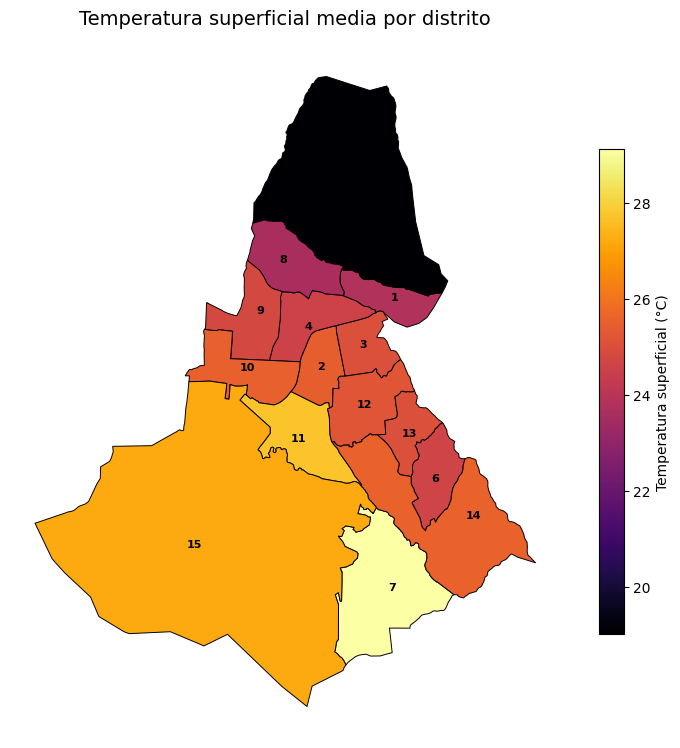

Mapa guardado: /content/drive/MyDrive/Microclimas_Cochabamba/mapa_lst_distrital_2024.png


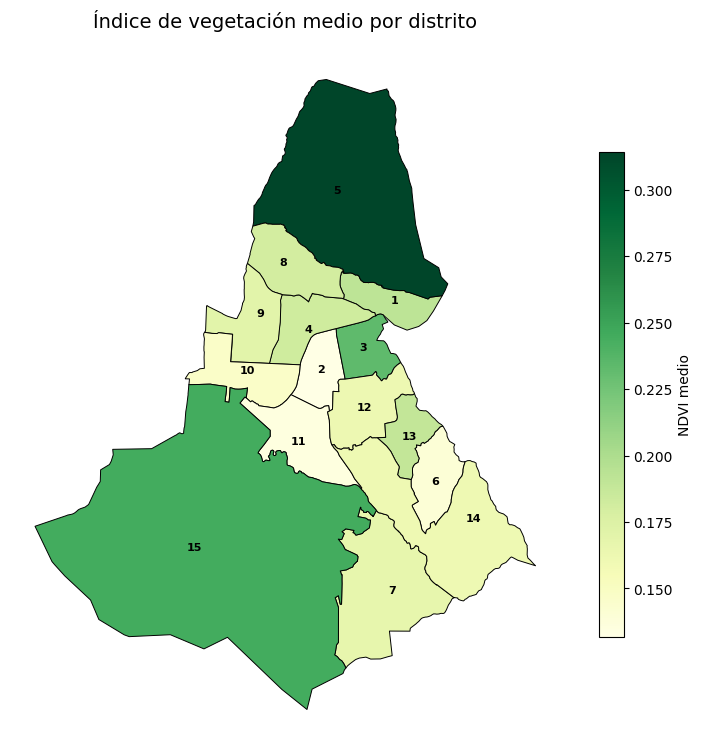

Mapa guardado: /content/drive/MyDrive/Microclimas_Cochabamba/mapa_ndvi_distrital_2024.png


In [88]:
import matplotlib.pyplot as plt
import os

# Puntos interiores de cada distrito para colocar las etiquetas
puntos = (
    gdf_indicadores
    .to_crs("EPSG:32719")
    .geometry
    .representative_point()
    .to_crs(gdf_indicadores.crs)
)

# Configuración de los dos mapas
mapas = [
    {
        "columna": "LST_C_mean",
        "titulo": "Temperatura superficial media por distrito",
        "leyenda": "Temperatura superficial (°C)",
        "cmap": "inferno",
        "archivo": "mapa_lst_distrital_2024.png"
    },
    {
        "columna": "NDVI_mean",
        "titulo": "Índice de vegetación medio por distrito",
        "leyenda": "NDVI medio",
        "cmap": "YlGn",
        "archivo": "mapa_ndvi_distrital_2024.png"
    }
]

for mapa in mapas:
    fig, ax = plt.subplots(figsize=(10, 9))

    gdf_indicadores.plot(
        column=mapa["columna"],
        cmap=mapa["cmap"],
        legend=True,
        edgecolor="black",
        linewidth=0.7,
        ax=ax,
        legend_kwds={
            "label": mapa["leyenda"],
            "shrink": 0.7
        }
    )

    for i, punto in enumerate(puntos):
        ax.annotate(
            str(i + 1),
            (punto.x, punto.y),
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold",
            color="black"
        )

    ax.set_title(mapa["titulo"], fontsize=14, pad=15)
    ax.set_axis_off()

    ruta = os.path.join(carpeta, mapa["archivo"])
    plt.savefig(ruta, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Mapa guardado:", ruta)

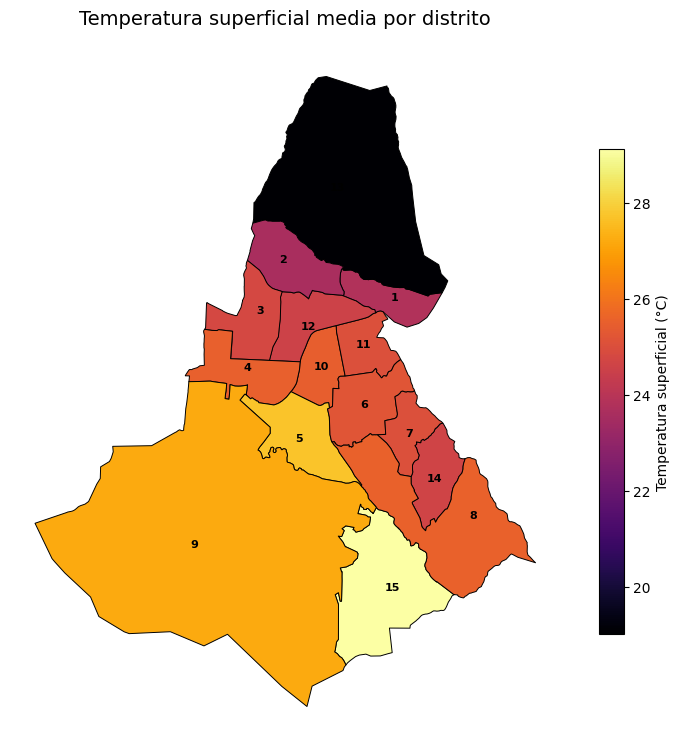

Mapa actualizado: /content/drive/MyDrive/Microclimas_Cochabamba/mapa_lst_distrital_2024.png


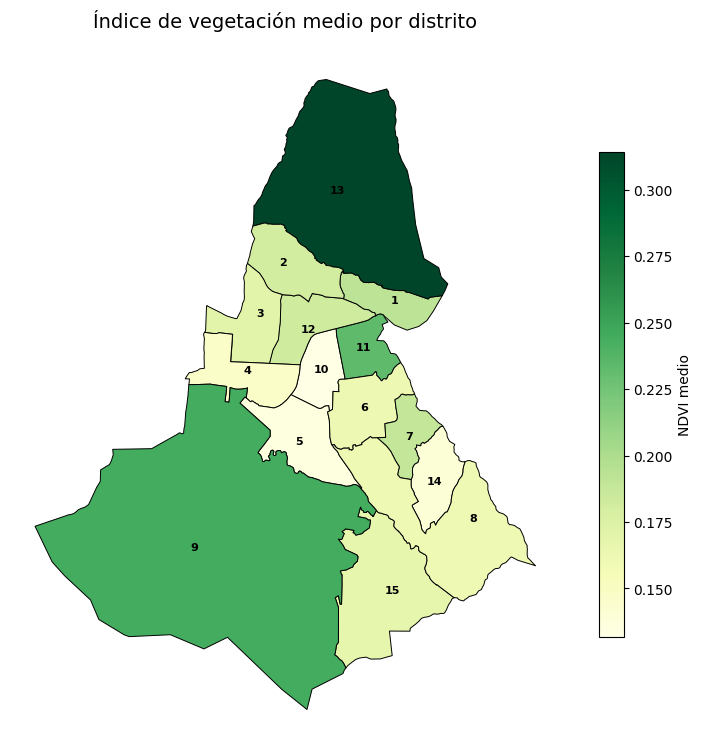

Mapa actualizado: /content/drive/MyDrive/Microclimas_Cochabamba/mapa_ndvi_distrital_2024.png


In [89]:
# Puntos interiores para ubicar las etiquetas
puntos = (
    gdf_indicadores
    .to_crs("EPSG:32719")
    .geometry
    .representative_point()
    .to_crs(gdf_indicadores.crs)
)

mapas = [
    {
        "columna": "LST_C_mean",
        "titulo": "Temperatura superficial media por distrito",
        "leyenda": "Temperatura superficial (°C)",
        "cmap": "inferno",
        "archivo": "mapa_lst_distrital_2024.png"
    },
    {
        "columna": "NDVI_mean",
        "titulo": "Índice de vegetación medio por distrito",
        "leyenda": "NDVI medio",
        "cmap": "YlGn",
        "archivo": "mapa_ndvi_distrital_2024.png"
    }
]

for mapa in mapas:
    fig, ax = plt.subplots(figsize=(10, 9))

    gdf_indicadores.plot(
        column=mapa["columna"],
        cmap=mapa["cmap"],
        legend=True,
        edgecolor="black",
        linewidth=0.7,
        ax=ax,
        legend_kwds={
            "label": mapa["leyenda"],
            "shrink": 0.7
        }
    )

    for (_, distrito), punto in zip(gdf_indicadores.iterrows(), puntos):
        numero = str(distrito["nombre"]).replace("Distrito ", "")

        ax.annotate(
            numero,
            (punto.x, punto.y),
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold",
            color="black"
        )

    ax.set_title(mapa["titulo"], fontsize=14, pad=15)
    ax.set_axis_off()

    ruta = os.path.join(carpeta, mapa["archivo"])
    plt.savefig(ruta, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Mapa actualizado:", ruta)

In [90]:
documentacion = """
# LABORATORIO DE INTELIGENCIA DE MICROCLIMAS DE COCHABAMBA
## Documentación del conjunto de datos ambientales – 2024

### 1. Objetivo
Caracterizar las condiciones ambientales de los 15 distritos de
Cochabamba mediante indicadores de temperatura superficial terrestre
(LST) y vegetación (NDVI).

### 2. Datos y productos

- lst_cochabamba_2024_100m.tif:
  Raster de temperatura superficial terrestre, expresada en °C.

- ndvi_cochabamba_2024_100m.tif:
  Raster del índice de vegetación NDVI.

- indicadores_ambientales_distritales_2024.csv:
  Estadísticas de LST y NDVI calculadas para cada distrito.

- correlaciones_NDVI_LST_distritales_2024.csv:
  Correlaciones de Pearson entre NDVI y LST por distrito,
  con valores p y ajuste FDR de Benjamini-Hochberg.

- base_ambiental_consolidada_2024.csv:
  Tabla que integra indicadores ambientales y correlaciones.

- distritos_indicadores_ambientales_2024.geojson:
  Geometrías distritales asociadas a los indicadores ambientales.

- mapa_lst_distrital_2024.png:
  Mapa de temperatura superficial media por distrito.

- mapa_ndvi_distrital_2024.png:
  Mapa de NDVI medio por distrito.

### 3. Características espaciales

- Sistema de referencia de los rásteres: EPSG:32719.
- Resolución de análisis: 100 metros.
- Dimensiones de los rásteres: 227 × 284 píxeles.
- Distritos analizados: 15.
- Los GeoTIFF de LST y NDVI comparten extensión, resolución y
  transformación espacial.

### 4. Indicadores calculados

Para cada distrito se calcularon:

- LST media, mediana, mínima, máxima y desviación estándar.
- NDVI medio, mediana, mínimo, máximo y desviación estándar.
- Número de píxeles válidos.
- Correlación de Pearson entre NDVI y LST.
- Valor p original.
- Valor p ajustado mediante FDR.
- Indicador de significancia estadística con umbral 0.05.

### 5. Consideraciones metodológicas

- LST representa la temperatura de la superficie terrestre,
  no la temperatura del aire a dos metros de altura.
- La resolución de análisis de 100 metros corresponde a una
  cuadrícula armonizada. No implica que el sensor térmico original
  tenga una resolución nativa de 100 metros.
- NDVI es un indicador espectral de vegetación; no constituye
  un inventario exacto de árboles ni de áreas verdes.
- La correlación entre NDVI y LST no demuestra causalidad.
- Los valores p de Pearson no consideran explícitamente la
  autocorrelación espacial entre píxeles. El ajuste FDR controla
  comparaciones múltiples, pero no corrige esa dependencia espacial.
- Los límites distritales proceden de una capa geográfica pública
  utilizada en el análisis y no deben presentarse como límites
  oficiales validados por el GAMC.

### 6. Uso recomendado

Estos productos permiten explorar diferencias territoriales,
identificar patrones ambientales y orientar análisis posteriores.
Deben complementarse con mediciones de temperatura del aire,
datos municipales de áreas verdes y validación en campo antes
de utilizarlos como fundamento de intervenciones específicas.

### 7. Año de referencia

2024.
"""

ruta_documentacion = os.path.join(
    carpeta,
    "documentacion_metodologica_2024.md"
)

with open(ruta_documentacion, "w", encoding="utf-8") as archivo:
    archivo.write(documentacion)

print("Documentación guardada correctamente:")
print(ruta_documentacion)

Documentación guardada correctamente:
/content/drive/MyDrive/Microclimas_Cochabamba/documentacion_metodologica_2024.md


In [91]:
import os
import zipfile

archivos_finales = [
    "lst_cochabamba_2024_100m.tif",
    "ndvi_cochabamba_2024_100m.tif",
    "indicadores_ambientales_distritales_2024.csv",
    "correlaciones_NDVI_LST_distritales_2024.csv",
    "base_ambiental_consolidada_2024.csv",
    "distritos_indicadores_ambientales_2024.geojson",
    "mapa_lst_distrital_2024.png",
    "mapa_ndvi_distrital_2024.png",
    "documentacion_metodologica_2024.md"
]

faltantes = [
    nombre for nombre in archivos_finales
    if not os.path.exists(os.path.join(carpeta, nombre))
]

if faltantes:
    print("Faltan estos archivos:")
    for nombre in faltantes:
        print("-", nombre)
else:
    ruta_zip = os.path.join(
        carpeta,
        "paquete_datos_microclimas_cochabamba_2024.zip"
    )

    with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as zipf:
        for nombre in archivos_finales:
            zipf.write(
                os.path.join(carpeta, nombre),
                arcname=nombre
            )

    print("Paquete creado correctamente:")
    print(ruta_zip)
    print("Archivos incluidos:", len(archivos_finales))
    print("Tamaño (MB):", round(os.path.getsize(ruta_zip) / (1024**2), 2))

Paquete creado correctamente:
/content/drive/MyDrive/Microclimas_Cochabamba/paquete_datos_microclimas_cochabamba_2024.zip
Archivos incluidos: 9
Tamaño (MB): 0.9
